In [ ]:
# Step 1: Install required libraries

!pip install -q kagglehub opencv-python-headless scikit-learn pandas matplotlib seaborn

In [ ]:
# Step 2: Import libraries and mount Google Drive

import os
import glob
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import kagglehub

from sklearn.model_selection import train_test_split

from google.colab import drive

drive.mount('/content/drive')

print("TensorFlow version:", tf.__version__)
print("OpenCV version:", cv2.__version__)
print("GPU available:", len(tf.config.list_physical_devices('GPU')) > 0)

Mounted at /content/drive
TensorFlow version: 2.21.0
OpenCV version: 4.14.0
GPU available: True


In [ ]:
# Step 3: Create project directories

PROJECT_DIR = "/content/drive/MyDrive/Satellite-Image-Project"

os.makedirs(PROJECT_DIR, exist_ok=True)

os.makedirs(
    os.path.join(PROJECT_DIR, "models"),
    exist_ok=True
)

os.makedirs(
    os.path.join(PROJECT_DIR, "logs"),
    exist_ok=True
)

print("Project directory:", PROJECT_DIR)
print("Project folders created successfully!")

Project directory: /content/drive/MyDrive/Satellite-Image-Project
Project folders created successfully!


In [ ]:
# Step 4: Download the DeepGlobe land-cover dataset

dataset_root = kagglehub.dataset_download(
    "balraj98/deepglobe-land-cover-classification-dataset"
)

print("Dataset downloaded successfully!")
print("Dataset location:", dataset_root)

100%|██████████| 2.74G/2.74G [00:27<00:00, 105MB/s]

Extracting files...


Dataset downloaded successfully!
Dataset location: /root/.cache/kagglehub/datasets/balraj98/deepglobe-land-cover-classification-dataset/versions/2


In [ ]:
# Step 5: Locate satellite images and corresponding masks

all_satellite_images = glob.glob(
    os.path.join(dataset_root, "**", "*_sat.jpg"),
    recursive=True
)

train_images_all = [
    path for path in all_satellite_images
    if "/train/" in path.replace("\\", "/").lower()
]

image_mask_pairs = []

for image_path in train_images_all:

    mask_path = image_path.replace(
        "_sat.jpg",
        "_mask.png"
    )

    if os.path.exists(mask_path):
        image_mask_pairs.append(
            (image_path, mask_path)
        )

print("Total satellite images found:", len(train_images_all))
print("Total matched image-mask pairs:", len(image_mask_pairs))

assert len(image_mask_pairs) > 0, (
    "No matched training pairs found. Check the dataset directory."
)

Total satellite images found: 803
Total matched image-mask pairs: 803


In [ ]:
# Step 6: Load class dictionary and create RGB mappings

class_csv_files = glob.glob(
    os.path.join(dataset_root, "**", "class_dict.csv"),
    recursive=True
)

assert len(class_csv_files) > 0, "class_dict.csv not found!"

class_df = pd.read_csv(class_csv_files[0])

print("Class dictionary:")
display(class_df)

# Create class names and RGB-to-class mapping
class_names = class_df["name"].tolist()

color_to_id = {}

for class_id, row in class_df.iterrows():

    rgb_color = (
        int(row["r"]),
        int(row["g"]),
        int(row["b"])
    )

    color_to_id[rgb_color] = class_id

id_to_color = {
    class_id: color
    for color, class_id in color_to_id.items()
}

NUM_CLASSES = 7
IMAGE_SIZE = 256
BATCH_SIZE = 8

print("\nClass names:", class_names)
print("Number of classes:", NUM_CLASSES)
print("Image size:", IMAGE_SIZE)

Class dictionary:


,name,r,g,b
0,urban_land,0,255,255
1,agriculture_land,255,255,0
2,rangeland,255,0,255
3,forest_land,0,255,0
4,water,0,0,255
5,barren_land,255,255,255
6,unknown,0,0,0



Class names: ['urban_land', 'agriculture_land', 'rangeland', 'forest_land', 'water', 'barren_land', 'unknown']
Number of classes: 7
Image size: 256


In [ ]:
# Step 7: Split matched image-mask pairs into training and validation sets

image_paths = [
    pair[0] for pair in image_mask_pairs
]

mask_paths = [
    pair[1] for pair in image_mask_pairs
]

train_images, val_images, train_masks, val_masks = train_test_split(
    image_paths,
    mask_paths,
    test_size=0.20,
    random_state=42
)

print("Training images:", len(train_images))
print("Validation images:", len(val_images))

Training images: 642
Validation images: 161


In [ ]:
# Step 8: Define image enhancement and mask preprocessing

def preprocess_image(image_path, mask_path):

    # Read satellite image
    image = cv2.imread(image_path)

    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    # Resize image
    image = cv2.resize(
        image,
        (IMAGE_SIZE, IMAGE_SIZE)
    )

    # Apply Gaussian Blur
    image = cv2.GaussianBlur(
        image,
        (5, 5),
        0
    )

    # Convert RGB to LAB
    lab_image = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2LAB
    )

    # Apply CLAHE to L channel
    l_channel, a_channel, b_channel = cv2.split(
        lab_image
    )

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    enhanced_l = clahe.apply(l_channel)

    enhanced_lab = cv2.merge(
        (enhanced_l, a_channel, b_channel)
    )

    # Convert LAB back to RGB
    enhanced_image = cv2.cvtColor(
        enhanced_lab,
        cv2.COLOR_LAB2RGB
    )

    # Normalize
    enhanced_image = enhanced_image.astype(
        np.float32
    ) / 255.0

    # Read ground-truth mask
    mask = cv2.imread(mask_path)

    mask = cv2.cvtColor(
        mask,
        cv2.COLOR_BGR2RGB
    )

    # Resize mask using nearest-neighbour interpolation
    mask = cv2.resize(
        mask,
        (IMAGE_SIZE, IMAGE_SIZE),
        interpolation=cv2.INTER_NEAREST
    )

    # Convert RGB colours into class IDs
    mask_key = (
        (mask[:, :, 0].astype(np.uint32) << 16)
        | (mask[:, :, 1].astype(np.uint32) << 8)
        | mask[:, :, 2].astype(np.uint32)
    )

    class_mask = np.full(
        (IMAGE_SIZE, IMAGE_SIZE),
        6,
        dtype=np.uint8
    )

    for rgb_color, class_id in color_to_id.items():

        color_key = (
            (rgb_color[0] << 16)
            | (rgb_color[1] << 8)
            | rgb_color[2]
        )

        class_mask[mask_key == color_key] = class_id

    return enhanced_image, class_mask

Image shape: (256, 256, 3)
Mask shape: (256, 256)
Image minimum: 0.0627451
Image maximum: 1.0
Classes found in mask: [0 1 2 3 4 5]


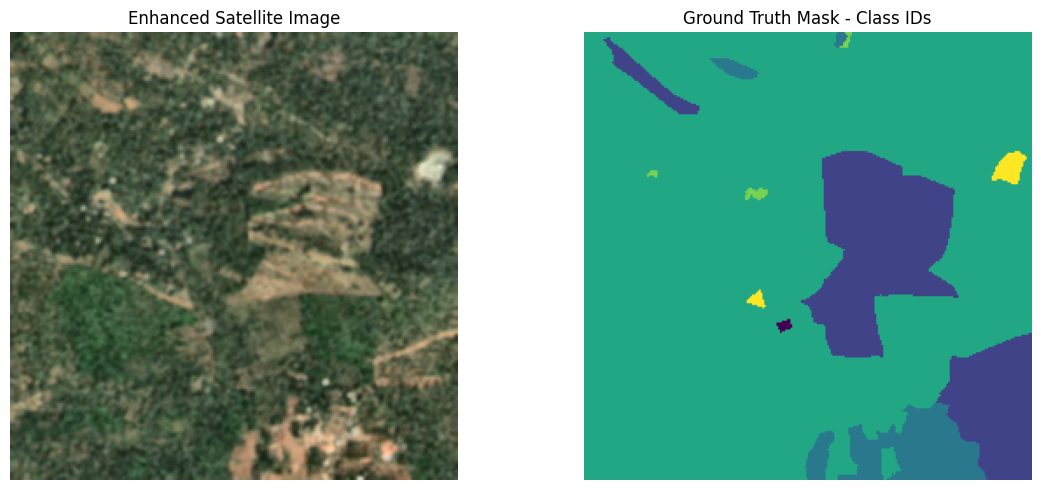

In [ ]:
# Step 9: Test image preprocessing

test_image_path = train_images[0]
test_mask_path = train_masks[0]

test_image, actual_mask = preprocess_image(
    test_image_path,
    test_mask_path
)

print("Image shape:", test_image.shape)
print("Mask shape:", actual_mask.shape)

print("Image minimum:", test_image.min())
print("Image maximum:", test_image.max())

print("Classes found in mask:", np.unique(actual_mask))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(test_image)
plt.title("Enhanced Satellite Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(actual_mask)
plt.title("Ground Truth Mask - Class IDs")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Step 10: Create the TensorFlow data generator

def data_generator(image_list, mask_list):

    for image_path, mask_path in zip(
        image_list,
        mask_list
    ):

        image, mask = preprocess_image(
            image_path,
            mask_path
        )

        yield image, mask.astype(np.int32)


print("Data generator created successfully!")

Data generator created successfully!


In [ ]:
# Step 11: Create TensorFlow training and validation datasets

AUTOTUNE = tf.data.AUTOTUNE

output_signature = (
    tf.TensorSpec(
        shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
        dtype=tf.float32
    ),

    tf.TensorSpec(
        shape=(IMAGE_SIZE, IMAGE_SIZE),
        dtype=tf.int32
    )
)

train_dataset = tf.data.Dataset.from_generator(
    lambda: data_generator(train_images, train_masks),
    output_signature=output_signature
)

val_dataset = tf.data.Dataset.from_generator(
    lambda: data_generator(val_images, val_masks),
    output_signature=output_signature
)

train_dataset = (
    train_dataset
    .shuffle(buffer_size=len(train_images))
    .batch(BATCH_SIZE, drop_remainder=True)
    .prefetch(AUTOTUNE)
)

val_dataset = (
    val_dataset
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

STEPS_PER_EPOCH = len(train_images) // BATCH_SIZE

VALIDATION_STEPS = int(
    np.ceil(len(val_images) / BATCH_SIZE)
)

print("Training dataset created successfully!")
print("Validation dataset created successfully!")

print("Steps per epoch:", STEPS_PER_EPOCH)
print("Validation steps:", VALIDATION_STEPS)

Training dataset created successfully!
Validation dataset created successfully!
Steps per epoch: 80
Validation steps: 21


In [ ]:
# Step 12: Define moderated class weights

new_class_weights = np.array([
    0.9357,  # urban_land
    0.4032,  # agriculture_land
    1.0573,  # rangeland
    0.8824,  # forest_land
    1.6775,  # water
    1.0439,  # barren_land
    0.0000   # unknown
], dtype=np.float32)

new_class_weights_tensor = tf.constant(
    new_class_weights,
    dtype=tf.float32
)

print("Moderated class weights:\n")

for class_id, weight in enumerate(new_class_weights):
    print(f"{class_names[class_id]:20s}: {weight:.4f}")

Moderated class weights:

urban_land          : 0.9357
agriculture_land    : 0.4032
rangeland           : 1.0573
forest_land         : 0.8824
water               : 1.6775
barren_land         : 1.0439
unknown             : 0.0000


In [ ]:
# Step 13: Define improved weighted loss function

def improved_weighted_loss(y_true, y_pred):

    y_true = tf.cast(
        y_true,
        tf.int32
    )

    # Calculate loss for every pixel
    pixel_loss = tf.keras.losses.sparse_categorical_crossentropy(
        y_true,
        y_pred
    )

    # Obtain class weight for every pixel
    pixel_weights = tf.gather(
        new_class_weights_tensor,
        y_true
    )

    # Apply class weights
    weighted_loss = pixel_loss * pixel_weights

    # Normalize by total pixel weight
    total_weight = tf.reduce_sum(pixel_weights)

    final_loss = tf.reduce_sum(weighted_loss) / (
        total_weight + tf.keras.backend.epsilon()
    )

    return final_loss


print("Improved weighted loss function created successfully!")

Improved weighted loss function created successfully!


In [ ]:
# Step 14: Define the U-Net architecture

def conv_block(inputs, filters):

    x = tf.keras.layers.Conv2D(
        filters,
        (3, 3),
        activation="relu",
        padding="same"
    )(inputs)

    x = tf.keras.layers.Conv2D(
        filters,
        (3, 3),
        activation="relu",
        padding="same"
    )(x)

    return x


def build_unet():

    inputs = tf.keras.layers.Input(
        shape=(IMAGE_SIZE, IMAGE_SIZE, 3)
    )

    # Encoder
    c1 = conv_block(inputs, 16)
    p1 = tf.keras.layers.MaxPooling2D((2, 2))(c1)

    c2 = conv_block(p1, 32)
    p2 = tf.keras.layers.MaxPooling2D((2, 2))(c2)

    c3 = conv_block(p2, 64)
    p3 = tf.keras.layers.MaxPooling2D((2, 2))(c3)

    c4 = conv_block(p3, 128)
    p4 = tf.keras.layers.MaxPooling2D((2, 2))(c4)

    # Bottleneck
    c5 = conv_block(p4, 256)

    # Decoder
    u6 = tf.keras.layers.UpSampling2D((2, 2))(c5)
    u6 = tf.keras.layers.Concatenate()([u6, c4])
    c6 = conv_block(u6, 128)

    u7 = tf.keras.layers.UpSampling2D((2, 2))(c6)
    u7 = tf.keras.layers.Concatenate()([u7, c3])
    c7 = conv_block(u7, 64)

    u8 = tf.keras.layers.UpSampling2D((2, 2))(c7)
    u8 = tf.keras.layers.Concatenate()([u8, c2])
    c8 = conv_block(u8, 32)

    u9 = tf.keras.layers.UpSampling2D((2, 2))(c8)
    u9 = tf.keras.layers.Concatenate()([u9, c1])
    c9 = conv_block(u9, 16)

    # Output layer
    outputs = tf.keras.layers.Conv2D(
        NUM_CLASSES,
        (1, 1),
        activation="softmax"
    )(c9)

    model = tf.keras.models.Model(
        inputs=inputs,
        outputs=outputs,
        name="Satellite_UNet"
    )

    return model


print("U-Net architecture defined successfully!")

U-Net architecture defined successfully!


In [ ]:
# Step 15: Build and compile the moderated weighted U-Net

moderated_model = build_unet()

moderated_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss=improved_weighted_loss,
    metrics=["accuracy"]
)

moderated_model.summary()

print("\nModerated weighted U-Net created successfully!")

Model: "Satellite_UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 256,  │        448 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 256, 256,  │      2,320 │ conv2d[0][0]      │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 128,  │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │      4,640 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │      9,248 │ conv2d_2[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 64,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │     18,496 │ max_pooling2d_1[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 64, 64,    │     36,928 │ conv2d_4[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 32, 32,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 32, 32,    │     73,856 │ max_pooling2d_2[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 32, 32,    │    147,584 │ conv2d_6[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 16, 16,    │          0 │ conv2d_7[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 16, 16,    │    295,168 │ max_pooling2d_3[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 16, 16,    │    590,080 │ conv2d_8[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d       │ (None, 32, 32,    │          0 │ conv2d_9[0][0]    │
│ (UpSampling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 32, 32,    │          0 │ up_sampling2d[0]

 Total params: 1,962,727 (7.49 MB)

 Trainable params: 1,962,727 (7.49 MB)

 Non-trainable params: 0 (0.00 B)


Moderated weighted U-Net created successfully!


In [ ]:
# Step 16: Configure training callbacks and persistent checkpoints

MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "models"
)

LOG_DIR = os.path.join(
    PROJECT_DIR,
    "logs"
)

BEST_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "best_moderated_satellite_unet.keras"
)

BACKUP_DIR = os.path.join(
    PROJECT_DIR,
    "training_backup"
)

moderated_callbacks = [

    tf.keras.callbacks.ModelCheckpoint(
        BEST_MODEL_PATH,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=0.00001,
        verbose=1
    ),

    tf.keras.callbacks.BackupAndRestore(
        backup_dir=BACKUP_DIR
    )
]

print("Training callbacks configured successfully!")
print("Best model will be saved at:", BEST_MODEL_PATH)
print("Training backup directory:", BACKUP_DIR)

Training callbacks configured successfully!
Best model will be saved at: /content/drive/MyDrive/Satellite-Image-Project/models/best_moderated_satellite_unet.keras
Training backup directory: /content/drive/MyDrive/Satellite-Image-Project/training_backup


In [ ]:
# Step 17: Train the moderated weighted U-Net model

moderated_history = moderated_model.fit(
    train_dataset.repeat(),
    validation_data=val_dataset,
    epochs=20,
    steps_per_epoch=STEPS_PER_EPOCH,
    callbacks=moderated_callbacks,
    verbose=1
)

print("\nModerated weighted U-Net training completed!")

Epoch 1/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.5258 - loss: 1.8294
Epoch 1: val_loss improved from None to 1.63515, saving model to /content/drive/MyDrive/Satellite-Image-Project/models/best_moderated_satellite_unet.keras


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: finished saving model to /content/drive/MyDrive/Satellite-Image-Project/models/best_moderated_satellite_unet.keras
80/80 ━━━━━━━━━━━━━━━━━━━━ 217s 938ms/step - accuracy: 0.5597 - loss: 1.7523 - val_accuracy: 0.6092 - val_loss: 1.6352 - learning_rate: 0.0010
Epoch 2/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 0.5714 - loss: 1.6895
Epoch 2: val_loss did not improve from 1.63515
80/80 ━━━━━━━━━━━━━━━━━━━━ 100s 563ms/step - accuracy: 0.5683 - loss: 1.6923 - val_accuracy: 0.6092 - val_loss: 1.6465 - learning_rate: 0.0010
Epoch 3/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.5757 - loss: 1.6639
Epoch 3: val_loss improved from 1.63515 to 1.63109, saving model to /content/drive/MyDrive/Satellite-Image-Project/models/best_moderated_satellite_unet.keras

Epoch 3: finished saving model to /content/drive/MyDrive/Satellite-Image-Project/models/best_moderated_satellite_unet.keras
80/80 ━━━━━━━━━━━━━━━━━━━━ 143s 877ms/step - accuracy: 0.5697 - loss: 1.6710 - val_accura

In [ ]:
# Step 18: Load and save the best moderated U-Net model

best_moderated_model = tf.keras.models.load_model(
    BEST_MODEL_PATH,
    custom_objects={
        "improved_weighted_loss": improved_weighted_loss
    }
)

FINAL_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "final_moderated_satellite_unet.keras"
)

best_moderated_model.save(FINAL_MODEL_PATH)

print("Best moderated U-Net loaded successfully!")
print("Final model saved successfully!")
print("Model location:", FINAL_MODEL_PATH)

Best moderated U-Net loaded successfully!
Final model saved successfully!
Model location: /content/drive/MyDrive/Satellite-Image-Project/models/final_moderated_satellite_unet.keras


In [ ]:

# Step 19: Evaluate the best moderated U-Net model

confusion_matrix = np.zeros(
    (NUM_CLASSES, NUM_CLASSES),
    dtype=np.int64
)

# Generate predictions for the complete validation dataset
for images, true_masks in val_dataset:

    predictions = best_moderated_model.predict(
        images,
        verbose=0
    )

    predicted_masks = np.argmax(
        predictions,
        axis=-1
    )

    true_masks = true_masks.numpy()

    # Calculate batch confusion matrix
    batch_cm = tf.math.confusion_matrix(
        true_masks.reshape(-1),
        predicted_masks.reshape(-1),
        num_classes=NUM_CLASSES
    ).numpy()

    confusion_matrix += batch_cm


# Calculate class-wise metrics
true_positives = np.diag(confusion_matrix)

actual_pixels = confusion_matrix.sum(axis=1)
predicted_pixels = confusion_matrix.sum(axis=0)

union = actual_pixels + predicted_pixels - true_positives

iou = np.divide(
    true_positives,
    union,
    out=np.full(NUM_CLASSES, np.nan),
    where=union != 0
)

dice = np.divide(
    2 * true_positives,
    actual_pixels + predicted_pixels,
    out=np.full(NUM_CLASSES, np.nan),
    where=(actual_pixels + predicted_pixels) != 0
)

# Overall metrics
pixel_accuracy = (
    true_positives.sum() / confusion_matrix.sum()
) * 100

mean_iou = np.nanmean(iou[:6]) * 100
mean_dice = np.nanmean(dice[:6]) * 100


# Display results
print("=" * 75)
print("MODERATED U-NET - CONFUSION MATRIX")
print("=" * 75)

print("Rows = Actual classes | Columns = Predicted classes")
print(confusion_matrix)

print("\n" + "=" * 75)
print("MODERATED U-NET - EVALUATION RESULTS")
print("=" * 75)

print(f"Pixel Accuracy : {pixel_accuracy:.2f}%")
print(f"Mean IoU       : {mean_iou:.2f}%")
print(f"Mean Dice      : {mean_dice:.2f}%")

print("\nCLASS-WISE PERFORMANCE")
print("-" * 75)

for i, class_name in enumerate(class_names):
    print(
        f"{class_name:<20} "
        f"IoU: {iou[i] * 100:>7.2f}% | "
        f"Dice: {dice[i] * 100:>7.2f}%"
    )


MODERATED U-NET - CONFUSION MATRIX
Rows = Actual classes | Columns = Predicted classes
[[ 637718  281520       0    3166    8097  155067       0]
 [ 357285 5683377       0  210278   83140   93723       0]
 [ 112548  606045      17   29824   27162   53903       0]
 [  12717  400820       1  538193   72391     454       0]
 [  29574   92298       0   14818  159917   48999       0]
 [ 135521  429391       0    2734    4911  261370       0]
 [   3210     639       0       8      68     392       0]]

MODERATED U-NET - EVALUATION RESULTS
Pixel Accuracy : 69.00%
Mean IoU       : 33.19%
Mean Dice      : 46.02%

CLASS-WISE PERFORMANCE
---------------------------------------------------------------------------
urban_land           IoU:   36.73% | Dice:   53.72%
agriculture_land     IoU:   68.99% | Dice:   81.65%
rangeland            IoU:    0.00% | Dice:    0.00%
forest_land          IoU:   41.87% | Dice:   59.03%
water                IoU:   29.54% | Dice:   45.61%
barren_land          IoU:   2

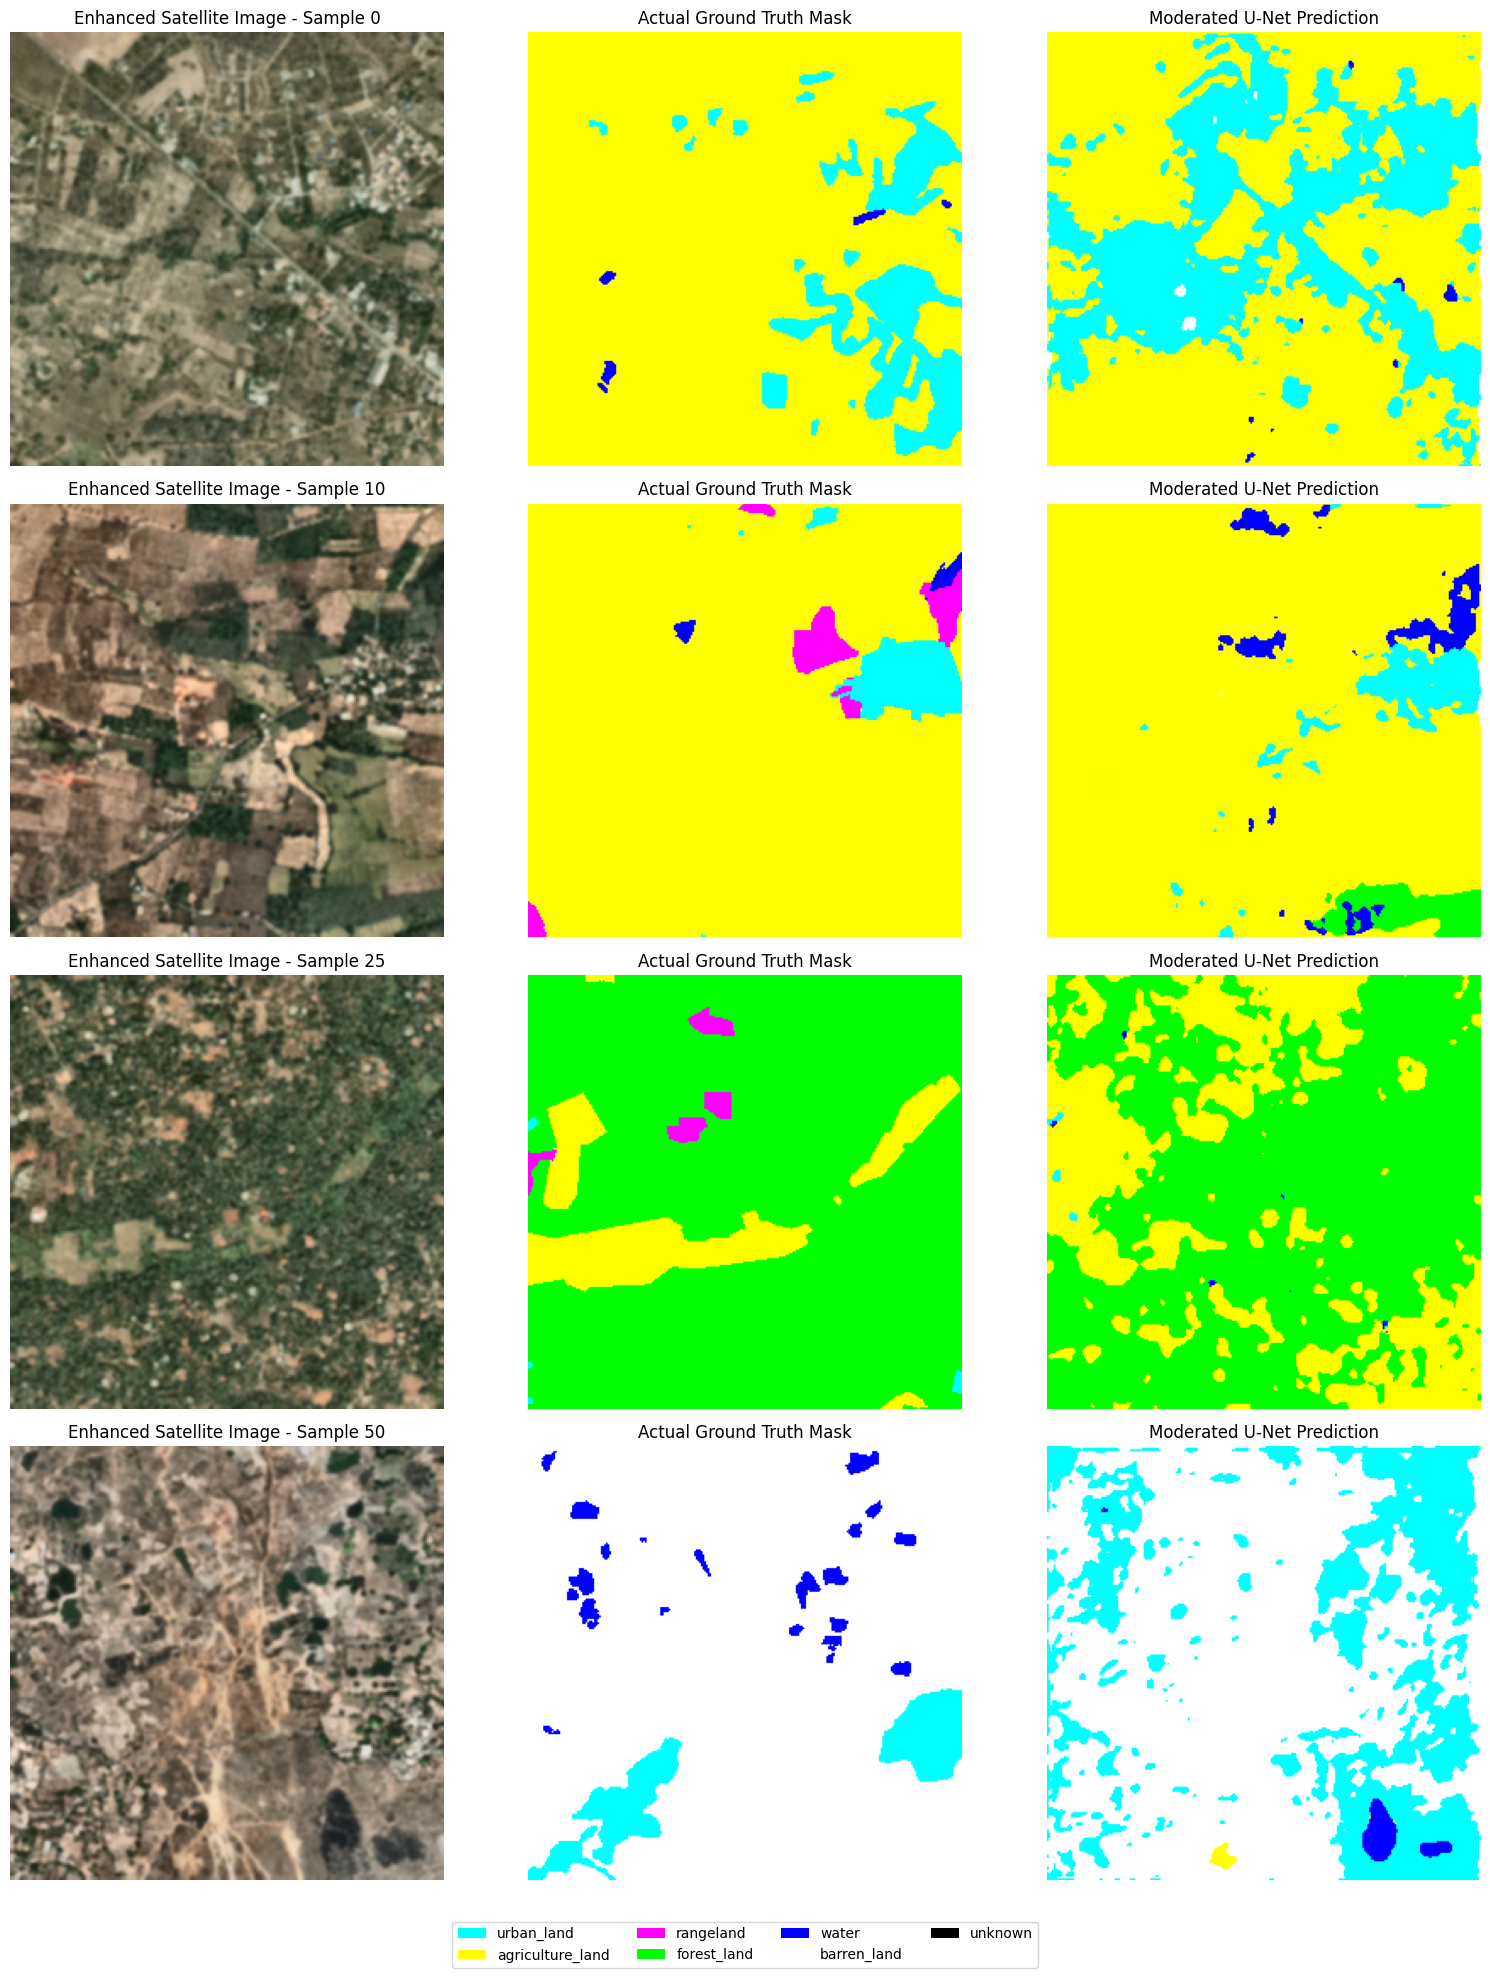

In [ ]:

# Step 20: Visual comparison of satellite images, actual masks, and predictions

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

# Select four validation samples
sample_indices = [0, 10, 25, 50]

# Create colour palette for all 7 classes
color_palette = np.array(
    [id_to_color[i] for i in range(NUM_CLASSES)],
    dtype=np.uint8
)

fig, axes = plt.subplots(
    len(sample_indices),
    3,
    figsize=(16, 5 * len(sample_indices))
)

for row, index in enumerate(sample_indices):

    # Load and preprocess the validation sample
    image, actual_mask = preprocess_image(
        val_images[index],
        val_masks[index]
    )

    # Generate model prediction
    prediction = best_moderated_model.predict(
        np.expand_dims(image, axis=0),
        verbose=0
    )

    predicted_mask = np.argmax(
        prediction[0],
        axis=-1
    )

    # Convert class IDs into RGB images
    actual_colored = color_palette[actual_mask]
    predicted_colored = color_palette[predicted_mask]

    # Display enhanced satellite image
    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"Enhanced Satellite Image - Sample {index}")

    # Display actual ground truth
    axes[row, 1].imshow(actual_colored)
    axes[row, 1].set_title("Actual Ground Truth Mask")

    # Display predicted segmentation
    axes[row, 2].imshow(predicted_colored)
    axes[row, 2].set_title("Moderated U-Net Prediction")

    for col in range(3):
        axes[row, col].axis("off")


# Add class legend
legend_elements = [
    Patch(
        facecolor=color_palette[i] / 255.0,
        label=class_names[i]
    )
    for i in range(NUM_CLASSES)
]

fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=4,
    bbox_to_anchor=(0.5, 0.01)
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()


CLASS-WISE PERFORMANCE AND PREDICTION DISTRIBUTION


,Class,Actual Pixels (%),Predicted Pixels (%),Precision (%),Recall (%),F1-Score (%)
0,urban_land,10.29,12.21,49.49,58.75,53.72
1,agriculture_land,60.92,71.03,75.84,88.42,81.65
2,rangeland,7.86,0.00,94.44,0.00,0.00
3,forest_land,9.71,7.57,67.36,52.53,59.03
4,water,3.28,3.37,44.96,46.27,45.61
5,barren_land,7.90,5.82,42.57,31.34,36.10
6,unknown,0.04,0.00,0.00,0.00,0.00


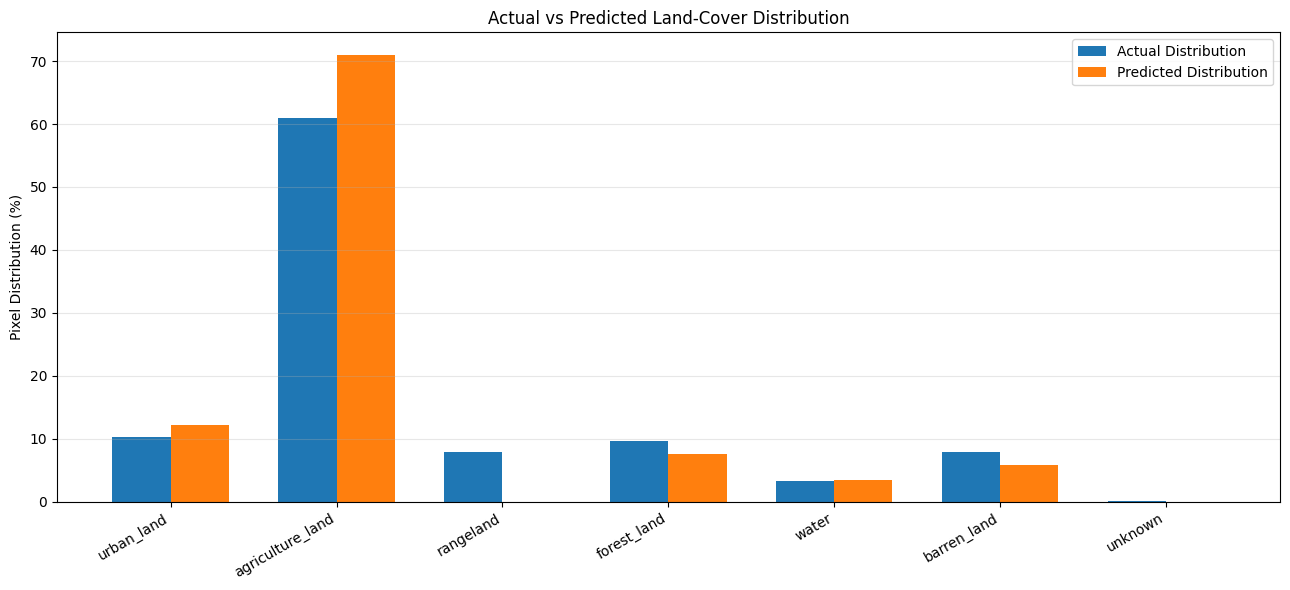

In [ ]:

# Step 21: Calculate class-wise precision, recall, F1-score, and pixel distribution

# Extract values from the confusion matrix
true_positives = np.diag(confusion_matrix)

actual_pixels = confusion_matrix.sum(axis=1)
predicted_pixels = confusion_matrix.sum(axis=0)

# Calculate precision and recall
precision = np.divide(
    true_positives,
    predicted_pixels,
    out=np.zeros(NUM_CLASSES, dtype=float),
    where=predicted_pixels != 0
)

recall = np.divide(
    true_positives,
    actual_pixels,
    out=np.zeros(NUM_CLASSES, dtype=float),
    where=actual_pixels != 0
)

# Calculate F1-score
f1_score = np.divide(
    2 * precision * recall,
    precision + recall,
    out=np.zeros(NUM_CLASSES, dtype=float),
    where=(precision + recall) != 0
)

# Calculate actual and predicted pixel percentages
total_pixels = confusion_matrix.sum()

actual_percentage = (actual_pixels / total_pixels) * 100
predicted_percentage = (predicted_pixels / total_pixels) * 100

# Create results table
class_analysis = pd.DataFrame({
    "Class": class_names,
    "Actual Pixels (%)": actual_percentage,
    "Predicted Pixels (%)": predicted_percentage,
    "Precision (%)": precision * 100,
    "Recall (%)": recall * 100,
    "F1-Score (%)": f1_score * 100
})

print("=" * 100)
print("CLASS-WISE PERFORMANCE AND PREDICTION DISTRIBUTION")
print("=" * 100)

display(
    class_analysis.round(2)
)

# Visualise actual vs predicted class distribution
x = np.arange(NUM_CLASSES)
width = 0.35

plt.figure(figsize=(13, 6))

plt.bar(
    x - width / 2,
    actual_percentage,
    width,
    label="Actual Distribution"
)

plt.bar(
    x + width / 2,
    predicted_percentage,
    width,
    label="Predicted Distribution"
)

plt.xticks(x, class_names, rotation=30, ha="right")
plt.ylabel("Pixel Distribution (%)")
plt.title("Actual vs Predicted Land-Cover Distribution")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:
# Step 22: Define new class weights with increased rangeland importance

experimental_class_weights = np.array(
    [
        0.9357,  # Urban
        0.4032,  # Agriculture
        2.5000,  # Rangeland - Increased weight
        0.8824,  # Forest
        1.6775,  # Water
        1.0439,  # Barren
        0.0000   # Unknown
    ],
    dtype=np.float32
)

experimental_weights_tensor = tf.constant(
    experimental_class_weights,
    dtype=tf.float32
)

print("Experimental Class Weights")
print("=" * 45)

for i, class_name in enumerate(class_names):
    print(
        f"{class_name:<20}: "
        f"{experimental_class_weights[i]:.4f}"
    )


Experimental Class Weights
urban_land          : 0.9357
agriculture_land    : 0.4032
rangeland           : 2.5000
forest_land         : 0.8824
water               : 1.6775
barren_land         : 1.0439
unknown             : 0.0000


In [ ]:
# Step 23: Define experimental weighted categorical crossentropy loss

def experimental_weighted_loss(y_true, y_pred):

    y_true = tf.cast(y_true, tf.int32)

    pixel_loss = tf.keras.losses.sparse_categorical_crossentropy(
        y_true,
        y_pred
    )

    pixel_weights = tf.gather(
        experimental_weights_tensor,
        y_true
    )

    weighted_loss = pixel_loss * pixel_weights

    return tf.reduce_sum(weighted_loss) / (
        tf.reduce_sum(pixel_weights) + tf.keras.backend.epsilon()
    )


print("Experimental weighted loss defined successfully!")

Experimental weighted loss defined successfully!


In [ ]:
# Step 24: Build the experimental U-Net model

experimental_model = build_unet()

experimental_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss=experimental_weighted_loss,
    metrics=["accuracy"]
)

print("Experimental U-Net created successfully!")
print("\nModel Summary:")

experimental_model.summary()

Experimental U-Net created successfully!

Model Summary:


Model: "Satellite_UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, 256, 256,  │        448 │ input_layer_1[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_20 (Conv2D)  │ (None, 256, 256,  │      2,320 │ conv2d_19[0][0]   │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 128, 128,  │          0 │ conv2d_20[0][0]   │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_21 (Conv2D)  │ (None, 128, 128,  │      4,640 │ max_pooling2d_4[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_22 (Conv2D)  │ (None, 128, 128,  │      9,248 │ conv2d_21[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_5     │ (None, 64, 64,    │          0 │ conv2d_22[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_23 (Conv2D)  │ (None, 64, 64,    │     18,496 │ max_pooling2d_5[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_24 (Conv2D)  │ (None, 64, 64,    │     36,928 │ conv2d_23[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_6     │ (None, 32, 32,    │          0 │ conv2d_24[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_25 (Conv2D)  │ (None, 32, 32,    │     73,856 │ max_pooling2d_6[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_26 (Conv2D)  │ (None, 32, 32,    │    147,584 │ conv2d_25[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_7     │ (None, 16, 16,    │          0 │ conv2d_26[0][0]   │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_27 (Conv2D)  │ (None, 16, 16,    │    295,168 │ max_pooling2d_7[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_28 (Conv2D)  │ (None, 16, 16,    │    590,080 │ conv2d_27[0][0]   │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_4     │ (None, 32, 32,    │          0 │ conv2d_28[0][0]   │
│ (UpSampling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_4       │ (None, 32, 32,    │          0 │ up_sampling2d_4[

 Total params: 1,962,727 (7.49 MB)

 Trainable params: 1,962,727 (7.49 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

# Step 25: Configure experimental model paths and callbacks

EXPERIMENTAL_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "best_rangeland_experimental_unet.keras"
)

EXPERIMENTAL_BACKUP_DIR = os.path.join(
    PROJECT_DIR,
    "experimental_training_backup"
)

experimental_callbacks = [

    # Save the model with the lowest validation loss
    tf.keras.callbacks.ModelCheckpoint(
        filepath=EXPERIMENTAL_MODEL_PATH,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    # Stop training if validation loss does not improve
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    # Reduce learning rate when validation loss stops improving
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=0.00001,
        verbose=1
    ),

    # Preserve training progress in Google Drive
    tf.keras.callbacks.BackupAndRestore(
        backup_dir=EXPERIMENTAL_BACKUP_DIR
    )
]

print("Experimental callbacks configured successfully!")
print("Best model path:", EXPERIMENTAL_MODEL_PATH)
print("Backup directory:", EXPERIMENTAL_BACKUP_DIR)


Experimental callbacks configured successfully!
Best model path: /content/drive/MyDrive/Satellite-Image-Project/models/best_rangeland_experimental_unet.keras
Backup directory: /content/drive/MyDrive/Satellite-Image-Project/experimental_training_backup


In [ ]:

# Step 26: Train the experimental U-Net with increased rangeland weight

experimental_history = experimental_model.fit(
    train_dataset.repeat(),
    validation_data=val_dataset,
    epochs=25,
    steps_per_epoch=STEPS_PER_EPOCH,
    callbacks=experimental_callbacks,
    verbose=1
)

print("\nExperimental U-Net training completed!")


Epoch 1/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.3468 - loss: 1.8007
Epoch 1: val_loss improved from None to 1.65090, saving model to /content/drive/MyDrive/Satellite-Image-Project/models/best_rangeland_experimental_unet.keras


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: finished saving model to /content/drive/MyDrive/Satellite-Image-Project/models/best_rangeland_experimental_unet.keras
80/80 ━━━━━━━━━━━━━━━━━━━━ 159s 608ms/step - accuracy: 0.4117 - loss: 1.7362 - val_accuracy: 0.6036 - val_loss: 1.6509 - learning_rate: 0.0010
Epoch 2/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.5607 - loss: 1.6489
Epoch 2: val_loss improved from 1.65090 to 1.63600, saving model to /content/drive/MyDrive/Satellite-Image-Project/models/best_rangeland_experimental_unet.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Satellite-Image-Project/models/best_rangeland_experimental_unet.keras
80/80 ━━━━━━━━━━━━━━━━━━━━ 114s 555ms/step - accuracy: 0.5404 - loss: 1.6544 - val_accuracy: 0.4421 - val_loss: 1.6360 - learning_rate: 0.0010
Epoch 3/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.5411 - loss: 1.6251
Epoch 3: val_loss improved from 1.63600 to 1.52467, saving model to /content/drive/MyDrive/Satellite-Image-Project/models/best_

In [ ]:

# Step 27: Load and save the best experimental U-Net model

best_experimental_model = tf.keras.models.load_model(
    EXPERIMENTAL_MODEL_PATH,
    custom_objects={
        "experimental_weighted_loss": experimental_weighted_loss
    }
)

FINAL_EXPERIMENTAL_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "final_rangeland_experimental_unet.keras"
)

best_experimental_model.save(
    FINAL_EXPERIMENTAL_MODEL_PATH
)

print("Best experimental U-Net loaded successfully!")
print("Final experimental model saved successfully!")
print("Model location:", FINAL_EXPERIMENTAL_MODEL_PATH)


Best experimental U-Net loaded successfully!
Final experimental model saved successfully!
Model location: /content/drive/MyDrive/Satellite-Image-Project/models/final_rangeland_experimental_unet.keras


In [ ]:

# Step 28: Evaluate the best experimental U-Net model

experimental_confusion_matrix = np.zeros(
    (NUM_CLASSES, NUM_CLASSES),
    dtype=np.int64
)

# Generate predictions for the complete validation dataset
for images, true_masks in val_dataset:

    predictions = best_experimental_model.predict(
        images,
        verbose=0
    )

    predicted_masks = np.argmax(
        predictions,
        axis=-1
    )

    true_masks = true_masks.numpy()

    # Calculate batch confusion matrix
    batch_cm = tf.math.confusion_matrix(
        true_masks.reshape(-1),
        predicted_masks.reshape(-1),
        num_classes=NUM_CLASSES
    ).numpy()

    experimental_confusion_matrix += batch_cm


# Calculate class-wise metrics
true_positives = np.diag(experimental_confusion_matrix)

actual_pixels = experimental_confusion_matrix.sum(axis=1)
predicted_pixels = experimental_confusion_matrix.sum(axis=0)

union = actual_pixels + predicted_pixels - true_positives

experimental_iou = np.divide(
    true_positives,
    union,
    out=np.full(NUM_CLASSES, np.nan),
    where=union != 0
)

experimental_dice = np.divide(
    2 * true_positives,
    actual_pixels + predicted_pixels,
    out=np.full(NUM_CLASSES, np.nan),
    where=(actual_pixels + predicted_pixels) != 0
)


# Calculate overall metrics
experimental_pixel_accuracy = (
    true_positives.sum() /
    experimental_confusion_matrix.sum()
) * 100

experimental_mean_iou = (
    np.nanmean(experimental_iou[:6]) * 100
)

experimental_mean_dice = (
    np.nanmean(experimental_dice[:6]) * 100
)


# Display confusion matrix
print("=" * 75)
print("EXPERIMENTAL U-NET - CONFUSION MATRIX")
print("=" * 75)

print("Rows = Actual classes | Columns = Predicted classes")
print(experimental_confusion_matrix)


# Display overall performance
print("\n" + "=" * 75)
print("EXPERIMENTAL U-NET - EVALUATION RESULTS")
print("=" * 75)

print(f"Pixel Accuracy : {experimental_pixel_accuracy:.2f}%")
print(f"Mean IoU       : {experimental_mean_iou:.2f}%")
print(f"Mean Dice      : {experimental_mean_dice:.2f}%")


# Display class-wise performance
print("\nCLASS-WISE PERFORMANCE")
print("-" * 75)

for i, class_name in enumerate(class_names):

    print(
        f"{class_name:<20} "
        f"IoU: {experimental_iou[i] * 100:>7.2f}% | "
        f"Dice: {experimental_dice[i] * 100:>7.2f}%"
    )


EXPERIMENTAL U-NET - CONFUSION MATRIX
Rows = Actual classes | Columns = Predicted classes
[[ 818467   69514  145854    4090     428   47215       0]
 [ 176383 4750664  994874  289026   86104  130752       0]
 [ 122575  415342  199513   44829    8949   38291       0]
 [  10635  256927   94953  653759    6250    2052       0]
 [   7959   48590   41142    8162  235678    4075       0]
 [ 186184  393407   70159    6865    5879  171433       0]
 [    824    1078     232      59       1    2123       0]]

EXPERIMENTAL U-NET - EVALUATION RESULTS
Pixel Accuracy : 64.73%
Mean IoU       : 39.78%
Mean Dice      : 53.71%

CLASS-WISE PERFORMANCE
---------------------------------------------------------------------------
urban_land           IoU:   51.47% | Dice:   67.96%
agriculture_land     IoU:   62.40% | Dice:   76.85%
rangeland            IoU:    9.17% | Dice:   16.79%
forest_land          IoU:   47.46% | Dice:   64.37%
water                IoU:   52.00% | Dice:   68.42%
barren_land          Io

In [ ]:

# Step 29: Compare all four U-Net models

model_comparison = pd.DataFrame({
    "Model": [
        "Original U-Net",
        "First Weighted U-Net",
        "Moderated U-Net",
        "Experimental U-Net"
    ],

    "Pixel Accuracy (%)": [
        67.34,
        37.29,
        69.00,
        experimental_pixel_accuracy
    ],

    "Mean IoU (%)": [
        27.78,
        20.01,
        33.19,
        experimental_mean_iou
    ],

    "Mean Dice (%)": [
        38.10,
        31.33,
        46.02,
        experimental_mean_dice
    ]
})

print("=" * 90)
print("FOUR-MODEL PERFORMANCE COMPARISON")
print("=" * 90)

display(
    model_comparison.style.format({
        "Pixel Accuracy (%)": "{:.2f}",
        "Mean IoU (%)": "{:.2f}",
        "Mean Dice (%)": "{:.2f}"
    }).highlight_max(
        subset=[
            "Pixel Accuracy (%)",
            "Mean IoU (%)",
            "Mean Dice (%)"
        ],
        color="lightgreen"
    )
)


# Compare class-wise IoU
class_iou_comparison = pd.DataFrame({
    "Class": class_names[:6],

    "Original U-Net": [
        40.43, 68.06, 0.00, 23.28, 34.31, 0.60
    ],

    "First Weighted U-Net": [
        43.17, 30.92, 7.46, 6.18, 21.66, 10.68
    ],

    "Moderated U-Net": [
        36.73, 68.99, 0.00, 41.87, 29.54, 22.03
    ],

    "Experimental U-Net": (
        experimental_iou[:6] * 100
    )
})

print("\nCLASS-WISE IoU COMPARISON")
print("=" * 90)

display(
    class_iou_comparison.style.format({
        "Original U-Net": "{:.2f}",
        "First Weighted U-Net": "{:.2f}",
        "Moderated U-Net": "{:.2f}",
        "Experimental U-Net": "{:.2f}"
    })
)


FOUR-MODEL PERFORMANCE COMPARISON


,Model,Pixel Accuracy (%),Mean IoU (%),Mean Dice (%)
0,Original U-Net,67.34,27.78,38.10
1,First Weighted U-Net,37.29,20.01,31.33
2,Moderated U-Net,69.00,33.19,46.02
3,Experimental U-Net,64.73,39.78,53.71



CLASS-WISE IoU COMPARISON


,Class,Original U-Net,First Weighted U-Net,Moderated U-Net,Experimental U-Net
0,urban_land,40.43,43.17,36.73,51.47
1,agriculture_land,68.06,30.92,68.99,62.40
2,rangeland,0.00,7.46,0.00,9.17
3,forest_land,23.28,6.18,41.87,47.46
4,water,34.31,21.66,29.54,52.00
5,barren_land,0.60,10.68,22.03,16.20


In [ ]:

# Step 30: Analyse experimental U-Net class distribution and misclassifications

cm = experimental_confusion_matrix

actual_pixels = cm.sum(axis=1)
predicted_pixels = cm.sum(axis=0)
correct_pixels = np.diag(cm)

total_pixels = cm.sum()

# Calculate actual and predicted class percentages
actual_distribution = (actual_pixels / total_pixels) * 100
predicted_distribution = (predicted_pixels / total_pixels) * 100

# Calculate precision and recall
precision = np.divide(
    correct_pixels,
    predicted_pixels,
    out=np.zeros(NUM_CLASSES, dtype=float),
    where=predicted_pixels != 0
) * 100

recall = np.divide(
    correct_pixels,
    actual_pixels,
    out=np.zeros(NUM_CLASSES, dtype=float),
    where=actual_pixels != 0
) * 100

# Create class-wise analysis table
distribution_df = pd.DataFrame({
    "Class": class_names,
    "Actual Pixels (%)": actual_distribution,
    "Predicted Pixels (%)": predicted_distribution,
    "Precision (%)": precision,
    "Recall (%)": recall,
    "IoU (%)": experimental_iou * 100
})

print("=" * 100)
print("EXPERIMENTAL U-NET - CLASS DISTRIBUTION ANALYSIS")
print("=" * 100)

display(
    distribution_df.style.format({
        "Actual Pixels (%)": "{:.2f}",
        "Predicted Pixels (%)": "{:.2f}",
        "Precision (%)": "{:.2f}",
        "Recall (%)": "{:.2f}",
        "IoU (%)": "{:.2f}"
    })
)


# Find the largest misclassification for each actual class
print("\n" + "=" * 100)
print("MAJOR CLASSIFICATION ERRORS")
print("=" * 100)

for i, class_name in enumerate(class_names[:6]):

    errors = cm[i].copy()
    errors[i] = 0

    wrong_class = np.argmax(errors)

    error_percentage = (
        errors[wrong_class] / actual_pixels[i]
    ) * 100

    print(
        f"{class_name:<20} -> "
        f"{class_names[wrong_class]:<20} "
        f"({error_percentage:.2f}% of actual pixels)"
    )


EXPERIMENTAL U-NET - CLASS DISTRIBUTION ANALYSIS


,Class,Actual Pixels (%),Predicted Pixels (%),Precision (%),Recall (%),IoU (%)
0,urban_land,10.29,12.54,61.86,75.40,51.47
1,agriculture_land,60.92,56.25,80.04,73.91,62.40
2,rangeland,7.86,14.66,12.90,24.05,9.17
3,forest_land,9.71,9.54,64.93,63.81,47.46
4,water,3.28,3.25,68.65,68.19,52.00
5,barren_land,7.90,3.75,43.30,20.56,16.20
6,unknown,0.04,0.00,0.00,0.00,0.00



MAJOR CLASSIFICATION ERRORS
urban_land           -> rangeland            (13.44% of actual pixels)
agriculture_land     -> rangeland            (15.48% of actual pixels)
rangeland            -> agriculture_land     (50.07% of actual pixels)
forest_land          -> agriculture_land     (25.08% of actual pixels)
water                -> agriculture_land     (14.06% of actual pixels)
barren_land          -> agriculture_land     (47.18% of actual pixels)


In [ ]:

# Step 31: Define combined Weighted Cross-Entropy and Dice Loss

def combined_weighted_dice_loss(y_true, y_pred):

    y_true = tf.cast(y_true, tf.int32)

    # ----------------------------------------
    # 1. Weighted Cross-Entropy Loss
    # ----------------------------------------

    pixel_loss = tf.keras.losses.sparse_categorical_crossentropy(
        y_true,
        y_pred
    )

    pixel_weights = tf.gather(
        experimental_weights_tensor,
        y_true
    )

    weighted_ce = tf.reduce_sum(
        pixel_loss * pixel_weights
    ) / (
        tf.reduce_sum(pixel_weights) +
        tf.keras.backend.epsilon()
    )

    # ----------------------------------------
    # 2. Prepare data for Dice Loss
    # ----------------------------------------

    # Ignore unknown class (class ID 6)
    valid_mask = tf.cast(
        y_true < 6,
        tf.float32
    )

    # One-hot encode the six known classes
    y_true_one_hot = tf.one_hot(
        y_true,
        depth=NUM_CLASSES
    )[..., :6]

    # Use probabilities for the six known classes
    y_pred_known = y_pred[..., :6]

    # Exclude unknown pixels
    valid_mask = tf.expand_dims(
        valid_mask,
        axis=-1
    )

    y_true_one_hot *= valid_mask
    y_pred_known *= valid_mask

    # ----------------------------------------
    # 3. Calculate class-wise Dice
    # ----------------------------------------

    intersection = tf.reduce_sum(
        y_true_one_hot * y_pred_known,
        axis=[0, 1, 2]
    )

    denominator = (
        tf.reduce_sum(y_true_one_hot, axis=[0, 1, 2]) +
        tf.reduce_sum(y_pred_known, axis=[0, 1, 2])
    )

    dice_score = (
        2.0 * intersection + 1e-6
    ) / (
        denominator + 1e-6
    )

    dice_loss = 1.0 - tf.reduce_mean(dice_score)

    # ----------------------------------------
    # 4. Combine both losses
    # ----------------------------------------

    total_loss = (
        0.5 * weighted_ce +
        0.5 * dice_loss
    )

    return total_loss


print("Combined Weighted Cross-Entropy + Dice Loss defined successfully!")


Combined Weighted Cross-Entropy + Dice Loss defined successfully!


In [ ]:

# Step 32: Build and compile the Combined Loss U-Net

combined_model = build_unet()

combined_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss=combined_weighted_dice_loss,
    metrics=["accuracy"]
)

print("Combined Loss U-Net created and compiled successfully!")

print("\nModel Summary:")
combined_model.summary()


Combined Loss U-Net created and compiled successfully!

Model Summary:


Model: "Satellite_UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_38 (Conv2D)  │ (None, 256, 256,  │        448 │ input_layer_2[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_39 (Conv2D)  │ (None, 256, 256,  │      2,320 │ conv2d_38[0][0]   │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_8     │ (None, 128, 128,  │          0 │ conv2d_39[0][0]   │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_40 (Conv2D)  │ (None, 128, 128,  │      4,640 │ max_pooling2d_8[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_41 (Conv2D)  │ (None, 128, 128,  │      9,248 │ conv2d_40[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_9     │ (None, 64, 64,    │          0 │ conv2d_41[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_42 (Conv2D)  │ (None, 64, 64,    │     18,496 │ max_pooling2d_9[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_43 (Conv2D)  │ (None, 64, 64,    │     36,928 │ conv2d_42[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_10    │ (None, 32, 32,    │          0 │ conv2d_43[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_44 (Conv2D)  │ (None, 32, 32,    │     73,856 │ max_pooling2d_10… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_45 (Conv2D)  │ (None, 32, 32,    │    147,584 │ conv2d_44[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_11    │ (None, 16, 16,    │          0 │ conv2d_45[0][0]   │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_46 (Conv2D)  │ (None, 16, 16,    │    295,168 │ max_pooling2d_11… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_47 (Conv2D)  │ (None, 16, 16,    │    590,080 │ conv2d_46[0][0]   │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_8     │ (None, 32, 32,    │          0 │ conv2d_47[0][0]   │
│ (UpSampling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_8       │ (None, 32, 32,    │          0 │ up_sampling2d_8[

 Total params: 1,962,727 (7.49 MB)

 Trainable params: 1,962,727 (7.49 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

# Step 33: Configure callbacks for Combined Loss U-Net

COMBINED_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "best_combined_loss_unet.keras"
)

COMBINED_BACKUP_DIR = os.path.join(
    PROJECT_DIR,
    "combined_training_backup"
)

combined_callbacks = [

    tf.keras.callbacks.ModelCheckpoint(
        filepath=COMBINED_MODEL_PATH,
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=0.00001,
        verbose=1
    ),

    tf.keras.callbacks.BackupAndRestore(
        backup_dir=COMBINED_BACKUP_DIR
    )
]

print("Combined Loss U-Net callbacks configured successfully!")
print("Best model path:", COMBINED_MODEL_PATH)
print("Training backup path:", COMBINED_BACKUP_DIR)


Combined Loss U-Net callbacks configured successfully!
Best model path: /content/drive/MyDrive/Satellite-Image-Project/models/best_combined_loss_unet.keras
Training backup path: /content/drive/MyDrive/Satellite-Image-Project/combined_training_backup


In [ ]:

# Step 34: Train the Combined Weighted Cross-Entropy + Dice Loss U-Net

combined_history = combined_model.fit(
    train_dataset,
    steps_per_epoch=STEPS_PER_EPOCH,
    validation_data=val_dataset,
    validation_steps=VALIDATION_STEPS,
    epochs=25,
    callbacks=combined_callbacks,
    verbose=1
)

print("\nCombined Loss U-Net training completed!")


Epoch 1/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.5183 - loss: 1.3261
Epoch 1: val_loss improved from None to 1.24888, saving model to /content/drive/MyDrive/Satellite-Image-Project/models/best_combined_loss_unet.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Satellite-Image-Project/models/best_combined_loss_unet.keras
80/80 ━━━━━━━━━━━━━━━━━━━━ 148s 426ms/step - accuracy: 0.5103 - loss: 1.2951 - val_accuracy: 0.6071 - val_loss: 1.2489 - learning_rate: 0.0010
Epoch 2/25


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 2: val_loss did not improve from 1.24888
80/80 ━━━━━━━━━━━━━━━━━━━━ 26s 325ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.6071 - val_loss: 1.2489 - learning_rate: 0.0010
Epoch 3/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.5383 - loss: 1.2627
Epoch 3: val_loss improved from 1.24888 to 1.23117, saving model to /content/drive/MyDrive/Satellite-Image-Project/models/best_combined_loss_unet.keras

Epoch 3: finished saving model to /content/drive/MyDrive/Satellite-Image-Project/models/best_combined_loss_unet.keras
80/80 ━━━━━━━━━━━━━━━━━━━━ 131s 415ms/step - accuracy: 0.5630 - loss: 1.2523 - val_accuracy: 0.6068 - val_loss: 1.2312 - learning_rate: 0.0010
Epoch 4/25

Epoch 4: val_loss did not improve from 1.23117
80/80 ━━━━━━━━━━━━━━━━━━━━ 27s 343ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.6068 - val_loss: 1.2312 - learning_rate: 0.0010
Epoch 5/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.5953 - loss: 1.2393
Epoch 5: 

In [ ]:

# Step 35: Load and save the best Combined Loss U-Net

COMBINED_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "best_combined_loss_unet.keras"
)

FINAL_COMBINED_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "final_combined_loss_unet.keras"
)

best_combined_model = tf.keras.models.load_model(
    COMBINED_MODEL_PATH,
    custom_objects={
        "combined_weighted_dice_loss": combined_weighted_dice_loss
    }
)

best_combined_model.save(FINAL_COMBINED_MODEL_PATH)

print("Best Combined Loss U-Net loaded successfully!")
print("Final model saved at:", FINAL_COMBINED_MODEL_PATH)


Best Combined Loss U-Net loaded successfully!
Final model saved at: /content/drive/MyDrive/Satellite-Image-Project/models/final_combined_loss_unet.keras


In [ ]:

# Step 36: Evaluate the Combined Loss U-Net on the validation dataset

combined_confusion_matrix = np.zeros(
    (NUM_CLASSES, NUM_CLASSES),
    dtype=np.int64
)

combined_correct_pixels = 0
combined_total_pixels = 0

for images, true_masks in val_dataset:

    # Predict segmentation masks
    predictions = best_combined_model.predict(
        images,
        verbose=0
    )

    predicted_masks = np.argmax(
        predictions,
        axis=-1
    )

    true_masks = true_masks.numpy()
    true_masks = np.squeeze(true_masks, axis=-1) if true_masks.ndim == 4 else true_masks

    # Update confusion matrix
    combined_confusion_matrix += tf.math.confusion_matrix(
        true_masks.flatten(),
        predicted_masks.flatten(),
        num_classes=NUM_CLASSES
    ).numpy()

    # Calculate pixel accuracy
    combined_correct_pixels += np.sum(
        true_masks == predicted_masks
    )

    combined_total_pixels += true_masks.size


# Calculate pixel accuracy
combined_pixel_accuracy = (
    combined_correct_pixels / combined_total_pixels
) * 100


# Calculate class-wise IoU and Dice
combined_iou = []
combined_dice = []

for i in range(NUM_CLASSES):

    tp = combined_confusion_matrix[i, i]

    actual = combined_confusion_matrix[i].sum()
    predicted = combined_confusion_matrix[:, i].sum()

    union = actual + predicted - tp

    iou = tp / union if union > 0 else 0

    dice = (
        2 * tp / (actual + predicted)
        if (actual + predicted) > 0
        else 0
    )

    combined_iou.append(iou)
    combined_dice.append(dice)


combined_iou = np.array(combined_iou)
combined_dice = np.array(combined_dice)

# Exclude unknown class from mean metrics
combined_mean_iou = np.mean(combined_iou[:6]) * 100
combined_mean_dice = np.mean(combined_dice[:6]) * 100


print("=" * 90)
print("COMBINED LOSS U-NET - EVALUATION RESULTS")
print("=" * 90)

print(f"Pixel Accuracy : {combined_pixel_accuracy:.2f}%")
print(f"Mean IoU       : {combined_mean_iou:.2f}%")
print(f"Mean Dice      : {combined_mean_dice:.2f}%")

print("\nCLASS-WISE IoU")
print("-" * 60)

for i, name in enumerate(class_names):
    print(f"{name:<20}: {combined_iou[i] * 100:.2f}%")

print("\nCONFUSION MATRIX")
print("=" * 90)
print(combined_confusion_matrix)

COMBINED LOSS U-NET - EVALUATION RESULTS
Pixel Accuracy : 54.52%
Mean IoU       : 16.64%
Mean Dice      : 23.20%

CLASS-WISE IoU
------------------------------------------------------------
urban_land          : 2.09%
agriculture_land    : 60.41%
rangeland           : 7.28%
forest_land         : 0.00%
water               : 30.06%
barren_land         : 0.00%
unknown             : 0.00%

CONFUSION MATRIX
[[  22943  538686  523939       0       0       0       0]
 [   1688 5398498 1026172       0    1445       0       0]
 [   2371  600047  225785       0    1296       0       0]
 [   1557  594047  425458       0    3514       0       0]
 [    825  137405  101615       0  105761       0       0]
 [   3616  636130  194181       0       0       0       0]
 [    247    2544    1526       0       0       0       0]]


In [ ]:

# Step 37: Inspect train and validation dataset batch consistency

print("=" * 80)
print("DATASET PIPELINE DIAGNOSTICS")
print("=" * 80)

print("\nTraining dataset:")
print("Dataset:", train_dataset)
print("Expected batches per epoch:", STEPS_PER_EPOCH)

print("\nValidation dataset:")
print("Dataset:", val_dataset)
print("Expected validation batches:", VALIDATION_STEPS)


# Inspect training batches
print("\n" + "=" * 80)
print("TRAINING BATCH INSPECTION")
print("=" * 80)

train_iterator = iter(train_dataset)

for batch_number in range(1, 4):

    try:
        images, masks = next(train_iterator)

        print(f"\nBatch {batch_number}")
        print("Image shape:", images.shape)
        print("Mask shape:", masks.shape)
        print("Image dtype:", images.dtype)
        print("Mask dtype:", masks.dtype)
        print("Image min/max:", float(tf.reduce_min(images)),
              float(tf.reduce_max(images)))
        print("Mask classes:", np.unique(masks.numpy()))

    except StopIteration:
        print("Training dataset ended unexpectedly!")
        break


# Inspect validation batches
print("\n" + "=" * 80)
print("VALIDATION BATCH INSPECTION")
print("=" * 80)

val_iterator = iter(val_dataset)

for batch_number in range(1, 4):

    try:
        images, masks = next(val_iterator)

        print(f"\nBatch {batch_number}")
        print("Image shape:", images.shape)
        print("Mask shape:", masks.shape)
        print("Mask classes:", np.unique(masks.numpy()))

    except StopIteration:
        print("Validation dataset ended unexpectedly!")
        break


DATASET PIPELINE DIAGNOSTICS

Training dataset:
Dataset: <_PrefetchDataset element_spec=(TensorSpec(shape=(8, 256, 256, 3), dtype=tf.float32, name=None), TensorSpec(shape=(8, 256, 256), dtype=tf.int32, name=None))>
Expected batches per epoch: 80

Validation dataset:
Dataset: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 256, 256, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 256, 256), dtype=tf.int32, name=None))>
Expected validation batches: 21

TRAINING BATCH INSPECTION

Batch 1
Image shape: (8, 256, 256, 3)
Mask shape: (8, 256, 256)
Image dtype: <dtype: 'float32'>
Mask dtype: <dtype: 'int32'>
Image min/max: 0.0 1.0
Mask classes: [0 1 2 3 4 5 6]

Batch 2
Image shape: (8, 256, 256, 3)
Mask shape: (8, 256, 256)
Image dtype: <dtype: 'float32'>
Mask dtype: <dtype: 'int32'>
Image min/max: 0.0 1.0
Mask classes: [0 1 2 3 4 5 6]

Batch 3
Image shape: (8, 256, 256, 3)
Mask shape: (8, 256, 256)
Image dtype: <dtype: 'float32'>
Mask dtype: <dtype: 'int32'>
Image min/max: 0.

In [ ]:

# Step 38: Make training and validation datasets repeatable

AUTOTUNE = tf.data.AUTOTUNE

# Repeat the existing training dataset
train_dataset = (
    train_dataset
    .repeat()
    .prefetch(AUTOTUNE)
)

# Repeat the existing validation dataset
val_dataset = (
    val_dataset
    .repeat()
    .prefetch(AUTOTUNE)
)

print("=" * 80)
print("UPDATED DATASET PIPELINE")
print("=" * 80)

print("\nTraining dataset cardinality:",
      tf.data.experimental.cardinality(train_dataset).numpy())

print("Validation dataset cardinality:",
      tf.data.experimental.cardinality(val_dataset).numpy())

print("\nTraining steps per epoch:", STEPS_PER_EPOCH)
print("Validation steps per epoch:", VALIDATION_STEPS)

print("\nDataset pipeline updated successfully!")


UPDATED DATASET PIPELINE

Training dataset cardinality: -1
Validation dataset cardinality: -1

Training steps per epoch: 80
Validation steps per epoch: 21

Dataset pipeline updated successfully!


In [ ]:

# Step 39: Verify continuous batch generation

train_iterator = iter(train_dataset)

total_batches_to_test = 85
successful_batches = 0

for batch_number in range(1, total_batches_to_test + 1):

    try:
        images, masks = next(train_iterator)

        assert images.shape == (BATCH_SIZE, IMAGE_SIZE, IMAGE_SIZE, 3)
        assert masks.shape == (BATCH_SIZE, IMAGE_SIZE, IMAGE_SIZE)

        assert np.isfinite(images.numpy()).all()

        successful_batches += 1

        if batch_number in [1, 80, 81, 85]:
            print(
                f"Batch {batch_number}: "
                f"Images {images.shape}, "
                f"Masks {masks.shape}"
            )

    except StopIteration:
        print(f"Dataset stopped unexpectedly at batch {batch_number}")
        break

print("\n" + "=" * 80)
print("BATCH CONTINUITY VERIFICATION")
print("=" * 80)

print("Expected batches:", total_batches_to_test)
print("Successfully generated:", successful_batches)

if successful_batches == total_batches_to_test:
    print("SUCCESS: Dataset continues beyond 80 batches!")
else:
    print("WARNING: Dataset continuity verification failed!")


Batch 1: Images (8, 256, 256, 3), Masks (8, 256, 256)
Batch 80: Images (8, 256, 256, 3), Masks (8, 256, 256)
Batch 81: Images (8, 256, 256, 3), Masks (8, 256, 256)
Batch 85: Images (8, 256, 256, 3), Masks (8, 256, 256)

BATCH CONTINUITY VERIFICATION
Expected batches: 85
Successfully generated: 85
SUCCESS: Dataset continues beyond 80 batches!


In [ ]:

# Step 40: Rebuild Combined Loss U-Net with corrected dataset pipeline

tf.keras.backend.clear_session()

combined_model = build_unet()

combined_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss=combined_weighted_dice_loss,
    metrics=["accuracy"]
)

print("Fresh Combined Loss U-Net created successfully!")
print("Total parameters:", combined_model.count_params())
print("Training steps per epoch:", STEPS_PER_EPOCH)
print("Validation steps per epoch:", VALIDATION_STEPS)


Fresh Combined Loss U-Net created successfully!
Total parameters: 1962727
Training steps per epoch: 80
Validation steps per epoch: 21


In [ ]:

# Step 41: Configure fresh callbacks for corrected Combined Loss training

COMBINED_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "best_combined_loss_unet_v2.keras"
)

COMBINED_BACKUP_DIR = os.path.join(
    PROJECT_DIR,
    "combined_training_backup_v2"
)

combined_callbacks = [

    tf.keras.callbacks.ModelCheckpoint(
        filepath=COMBINED_MODEL_PATH,
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=0.00001,
        verbose=1
    ),

    tf.keras.callbacks.BackupAndRestore(
        backup_dir=COMBINED_BACKUP_DIR
    )
]

print("Fresh training callbacks configured successfully!")
print("Best checkpoint:", COMBINED_MODEL_PATH)
print("Backup directory:", COMBINED_BACKUP_DIR)


Fresh training callbacks configured successfully!
Best checkpoint: /content/drive/MyDrive/Satellite-Image-Project/models/best_combined_loss_unet_v2.keras
Backup directory: /content/drive/MyDrive/Satellite-Image-Project/combined_training_backup_v2


In [ ]:

# Step 42: Train Combined Loss U-Net with corrected dataset pipeline

combined_history_v2 = combined_model.fit(
    train_dataset,
    steps_per_epoch=STEPS_PER_EPOCH,
    validation_data=val_dataset,
    validation_steps=VALIDATION_STEPS,
    epochs=25,
    callbacks=combined_callbacks,
    verbose=1
)

print("\nCorrected Combined Loss U-Net training completed!")

print("\nBest validation loss:",
      min(combined_history_v2.history["val_loss"]))

print("Best validation accuracy:",
      max(combined_history_v2.history["val_accuracy"]))


Epoch 1/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.2667 - loss: 1.3575
Epoch 1: val_loss improved from None to 1.25885, saving model to /content/drive/MyDrive/Satellite-Image-Project/models/best_combined_loss_unet_v2.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Satellite-Image-Project/models/best_combined_loss_unet_v2.keras
80/80 ━━━━━━━━━━━━━━━━━━━━ 161s 617ms/step - accuracy: 0.3596 - loss: 1.3203 - val_accuracy: 0.6069 - val_loss: 1.2589 - learning_rate: 0.0010
Epoch 2/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.5570 - loss: 1.2771
Epoch 2: val_loss improved from 1.25885 to 1.24739, saving model to /content/drive/MyDrive/Satellite-Image-Project/models/best_combined_loss_unet_v2.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Satellite-Image-Project/models/best_combined_loss_unet_v2.keras
80/80 ━━━━━━━━━━━━━━━━━━━━ 120s 576ms/step - accuracy: 0.5665 - loss: 1.2685 - val_accuracy: 0.6071 - val_loss: 1.2474 - learning_rate: 

In [ ]:

# Step 43: Load and save the best corrected Combined Loss U-Net

COMBINED_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "best_combined_loss_unet_v2.keras"
)

FINAL_COMBINED_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "final_combined_loss_unet_v2.keras"
)

best_combined_model = tf.keras.models.load_model(
    COMBINED_MODEL_PATH,
    custom_objects={
        "combined_weighted_dice_loss": combined_weighted_dice_loss
    }
)

best_combined_model.save(
    FINAL_COMBINED_MODEL_PATH
)

print("Best corrected Combined Loss U-Net loaded successfully!")
print("Final model saved at:", FINAL_COMBINED_MODEL_PATH)
print("Best validation loss:", min(combined_history_v2.history["val_loss"]))


Best corrected Combined Loss U-Net loaded successfully!
Final model saved at: /content/drive/MyDrive/Satellite-Image-Project/models/final_combined_loss_unet_v2.keras
Best validation loss: 0.9676341414451599


In [ ]:

# Step 44: Evaluate the corrected Combined Loss U-Net

# Initialize the confusion matrix
combined_confusion_matrix_v2 = np.zeros(
    (NUM_CLASSES, NUM_CLASSES),
    dtype=np.int64
)

combined_correct_pixels_v2 = 0
combined_total_pixels_v2 = 0

print("Starting evaluation of the corrected Combined Loss U-Net...")

# IMPORTANT: Take only 21 batches because val_dataset is repeated.
for batch_index, (images, true_masks) in enumerate(
    val_dataset.take(VALIDATION_STEPS)
):

    # Generate predictions
    predictions = best_combined_model.predict(
        images,
        verbose=0
    )

    # Convert probabilities into class IDs
    predicted_masks = np.argmax(
        predictions,
        axis=-1
    )

    # Convert tensors into NumPy arrays
    true_masks = true_masks.numpy()

    # Calculate confusion matrix for the current batch
    batch_confusion_matrix = tf.math.confusion_matrix(
        true_masks.flatten(),
        predicted_masks.flatten(),
        num_classes=NUM_CLASSES
    ).numpy()

    combined_confusion_matrix_v2 += batch_confusion_matrix

    # Calculate correct and total pixels
    combined_correct_pixels_v2 += np.sum(
        true_masks == predicted_masks
    )

    combined_total_pixels_v2 += true_masks.size

    print(
        f"Evaluated batch {batch_index + 1}/{VALIDATION_STEPS}",
        end="\r"
    )


# Calculate pixel accuracy
combined_pixel_accuracy_v2 = (
    combined_correct_pixels_v2 /
    combined_total_pixels_v2
) * 100


# Calculate class-wise IoU and Dice
combined_iou_v2 = []
combined_dice_v2 = []

for i in range(NUM_CLASSES):

    tp = combined_confusion_matrix_v2[i, i]

    actual = combined_confusion_matrix_v2[i].sum()
    predicted = combined_confusion_matrix_v2[:, i].sum()

    union = actual + predicted - tp

    iou = tp / union if union > 0 else 0

    dice = (
        (2 * tp) / (actual + predicted)
        if (actual + predicted) > 0
        else 0
    )

    combined_iou_v2.append(iou)
    combined_dice_v2.append(dice)


combined_iou_v2 = np.array(combined_iou_v2)
combined_dice_v2 = np.array(combined_dice_v2)


# Calculate mean metrics (exclude unknown class)
combined_mean_iou_v2 = np.mean(
    combined_iou_v2[:6]
) * 100

combined_mean_dice_v2 = np.mean(
    combined_dice_v2[:6]
) * 100


# Display evaluation results
print("\n")
print("=" * 90)
print("CORRECTED COMBINED LOSS U-NET - EVALUATION RESULTS")
print("=" * 90)

print(f"Total validation images: {combined_total_pixels_v2 // (IMAGE_SIZE * IMAGE_SIZE)}")
print(f"Total validation pixels: {combined_total_pixels_v2:,}")

print(f"\nPixel Accuracy : {combined_pixel_accuracy_v2:.2f}%")
print(f"Mean IoU       : {combined_mean_iou_v2:.2f}%")
print(f"Mean Dice      : {combined_mean_dice_v2:.2f}%")


# Display class-wise IoU and Dice
print("\nCLASS-WISE EVALUATION")
print("-" * 70)

for i, name in enumerate(class_names):

    print(
        f"{name:<20} | "
        f"IoU: {combined_iou_v2[i] * 100:6.2f}% | "
        f"Dice: {combined_dice_v2[i] * 100:6.2f}%"
    )


# Display confusion matrix
print("\nCONFUSION MATRIX")
print("=" * 90)
print("Rows = Actual classes | Columns = Predicted classes")
print(combined_confusion_matrix_v2)

print("\nEvaluation completed successfully!")


Starting evaluation of the corrected Combined Loss U-Net...


CORRECTED COMBINED LOSS U-NET - EVALUATION RESULTS
Total validation images: 161
Total validation pixels: 10,551,296

Pixel Accuracy : 64.48%
Mean IoU       : 33.46%
Mean Dice      : 46.60%

CLASS-WISE EVALUATION
----------------------------------------------------------------------
urban_land           | IoU:  45.11% | Dice:  62.18%
agriculture_land     | IoU:  63.35% | Dice:  77.56%
rangeland            | IoU:   7.93% | Dice:  14.70%
forest_land          | IoU:  36.15% | Dice:  53.11%
water                | IoU:  40.39% | Dice:  57.54%
barren_land          | IoU:   7.81% | Dice:  14.49%
unknown              | IoU:   0.00% | Dice:   0.00%

CONFUSION MATRIX
Rows = Actual classes | Columns = Predicted classes
[[ 758670  179712  118398    4429     549   23810       0]
 [ 212319 5104133  570524  462141   37292   41394       0]
 [ 106309  511553  130379   62238    6326   12694       0]
 [   9531  375798   53063  577684    8141   

Experimental U-Net loaded successfully!


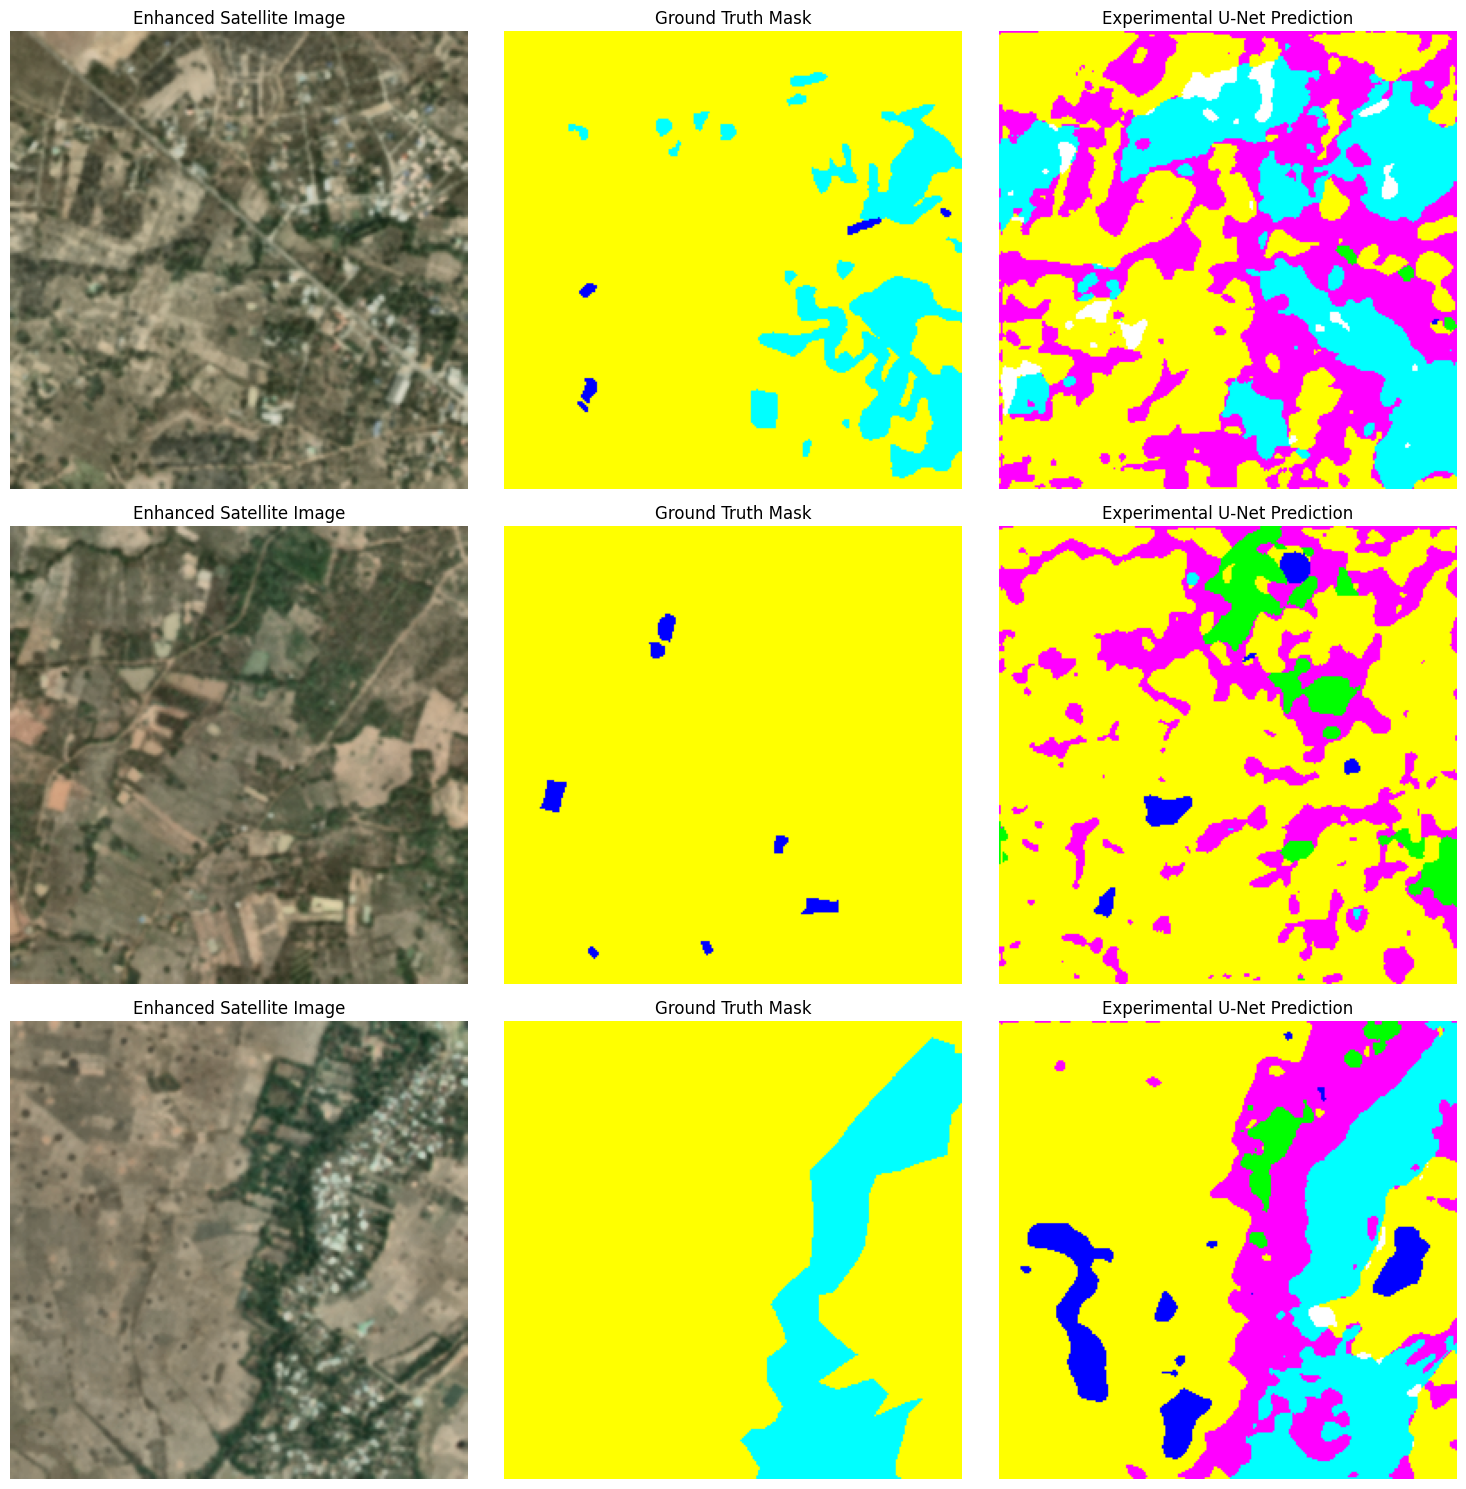


Visual prediction comparison completed!


In [ ]:

# Step 45: Visualize the best Experimental U-Net predictions

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
import os

# Load the selected Experimental U-Net
EXPERIMENTAL_FINAL_PATH = os.path.join(
    MODEL_DIR,
    "final_rangeland_experimental_unet.keras"
)

best_experimental_model = tf.keras.models.load_model(
    EXPERIMENTAL_FINAL_PATH,
    custom_objects={
        "experimental_weighted_loss": experimental_weighted_loss
    }
)

print("Experimental U-Net loaded successfully!")


# Get one batch from the validation dataset
images, true_masks = next(
    iter(val_dataset.take(1))
)

# Select three validation samples
sample_count = min(3, images.shape[0])

images = images[:sample_count].numpy()
true_masks = true_masks[:sample_count].numpy()


# Generate predictions
predictions = best_experimental_model.predict(
    images,
    verbose=0
)

predicted_masks = np.argmax(
    predictions,
    axis=-1
)


# Convert class IDs into RGB colours
color_palette = np.array(
    [id_to_color[i] for i in range(NUM_CLASSES)],
    dtype=np.uint8
)

def mask_to_rgb(mask):
    return color_palette[mask]


# Display results
fig, axes = plt.subplots(
    sample_count,
    3,
    figsize=(15, 5 * sample_count)
)

if sample_count == 1:
    axes = np.expand_dims(axes, axis=0)

for i in range(sample_count):

    # Enhanced satellite image
    axes[i, 0].imshow(images[i])
    axes[i, 0].set_title("Enhanced Satellite Image")

    # Ground-truth mask
    axes[i, 1].imshow(mask_to_rgb(true_masks[i]))
    axes[i, 1].set_title("Ground Truth Mask")

    # Predicted mask
    axes[i, 2].imshow(mask_to_rgb(predicted_masks[i]))
    axes[i, 2].set_title("Experimental U-Net Prediction")

    for j in range(3):
        axes[i, j].axis("off")


plt.tight_layout()
plt.show()


print("\nVisual prediction comparison completed!")


In [ ]:

# Step 46: Generate the final model performance report

import pandas as pd
import os

# Overall model performance
model_performance = pd.DataFrame({
    "Model": [
        "Original U-Net",
        "First Weighted U-Net",
        "Moderated U-Net",
        "Experimental U-Net",
        "Corrected Combined Loss U-Net"
    ],
    "Pixel Accuracy (%)": [
        67.34, 37.29, 69.00, 64.73, 64.48
    ],
    "Mean IoU (%)": [
        27.78, 20.01, 33.19, 39.78, 33.46
    ],
    "Mean Dice (%)": [
        38.10, 31.33, 46.02, 53.71, 46.60
    ]
})


# Class-wise IoU comparison
class_iou_comparison = pd.DataFrame({
    "Class": [
        "urban_land",
        "agriculture_land",
        "rangeland",
        "forest_land",
        "water",
        "barren_land"
    ],
    "Original U-Net": [
        40.43, 68.06, 0.00, 23.28, 34.31, 0.60
    ],
    "First Weighted U-Net": [
        43.17, 30.92, 7.46, 6.18, 21.66, 10.68
    ],
    "Moderated U-Net": [
        36.73, 68.99, 0.00, 41.87, 29.54, 22.03
    ],
    "Experimental U-Net": [
        51.47, 62.40, 9.17, 47.46, 52.00, 16.20
    ],
    "Corrected Combined Loss U-Net": [
        45.11, 63.35, 7.93, 36.15, 40.39, 7.81
    ]
})


# Create report directory
REPORT_DIR = os.path.join(PROJECT_DIR, "reports")
os.makedirs(REPORT_DIR, exist_ok=True)


# Save reports
model_performance.to_csv(
    os.path.join(REPORT_DIR, "model_performance_comparison.csv"),
    index=False
)

class_iou_comparison.to_csv(
    os.path.join(REPORT_DIR, "class_wise_iou_comparison.csv"),
    index=False
)


# Display reports
print("=" * 90)
print("OVERALL MODEL PERFORMANCE")
print("=" * 90)

display(model_performance)

print("\nCLASS-WISE IoU COMPARISON")
print("=" * 90)

display(class_iou_comparison)

print("\nReports saved successfully!")
print("Report directory:", REPORT_DIR)


OVERALL MODEL PERFORMANCE


,Model,Pixel Accuracy (%),Mean IoU (%),Mean Dice (%)
0,Original U-Net,67.34,27.78,38.10
1,First Weighted U-Net,37.29,20.01,31.33
2,Moderated U-Net,69.00,33.19,46.02
3,Experimental U-Net,64.73,39.78,53.71
4,Corrected Combined Loss U-Net,64.48,33.46,46.60



CLASS-WISE IoU COMPARISON


,Class,Original U-Net,First Weighted U-Net,Moderated U-Net,Experimental U-Net,Corrected Combined Loss U-Net
0,urban_land,40.43,43.17,36.73,51.47,45.11
1,agriculture_land,68.06,30.92,68.99,62.40,63.35
2,rangeland,0.00,7.46,0.00,9.17,7.93
3,forest_land,23.28,6.18,41.87,47.46,36.15
4,water,34.31,21.66,29.54,52.00,40.39
5,barren_land,0.60,10.68,22.03,16.20,7.81



Reports saved successfully!
Report directory: /content/drive/MyDrive/Satellite-Image-Project/reports


In [ ]:

# Step 47: Save project configuration and dataset splits

import os
import json
import pandas as pd

# Create project directories
CONFIG_DIR = os.path.join(PROJECT_DIR, "config")
os.makedirs(CONFIG_DIR, exist_ok=True)

# Selected final model
FINAL_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "final_rangeland_experimental_unet.keras"
)

# Verify the selected model exists
if not os.path.exists(FINAL_MODEL_PATH):
    raise FileNotFoundError(
        f"Final model not found: {FINAL_MODEL_PATH}"
    )

# Save class mapping
class_mapping = {
    "class_names": class_names,
    "id_to_color": {
        str(k): list(v)
        for k, v in id_to_color.items()
    },
    "color_to_id": {
        str(k): int(v)
        for k, v in color_to_id.items()
    }
}

# Save preprocessing and model configuration
project_config = {
    "project_name": "Automated Satellite Image Enhancement and Land-Cover Segmentation System",
    "selected_model": "Experimental U-Net",
    "model_path": FINAL_MODEL_PATH,
    "image_size": IMAGE_SIZE,
    "num_classes": NUM_CLASSES,
    "batch_size": BATCH_SIZE,
    "preprocessing": {
        "resize": [IMAGE_SIZE, IMAGE_SIZE],
        "gaussian_blur_kernel": [5, 5],
        "color_space": "LAB",
        "enhancement": "CLAHE",
        "clahe_clip_limit": 2.0,
        "clahe_tile_grid_size": [8, 8],
        "normalization": "Divide by 255"
    },
    "evaluation": {
        "pixel_accuracy": 64.73,
        "mean_iou": 39.78,
        "mean_dice": 53.71
    }
}

# Save class mapping JSON
with open(
    os.path.join(CONFIG_DIR, "class_mapping.json"),
    "w"
) as file:
    json.dump(class_mapping, file, indent=4)

# Save project configuration JSON
with open(
    os.path.join(CONFIG_DIR, "project_config.json"),
    "w"
) as file:
    json.dump(project_config, file, indent=4)


# Save train and validation dataset splits
train_split_df = pd.DataFrame({
    "image_path": list(map(str, train_images)),
    "mask_path": list(map(str, train_masks)),
    "split": "train"
})

val_split_df = pd.DataFrame({
    "image_path": list(map(str, val_images)),
    "mask_path": list(map(str, val_masks)),
    "split": "validation"
})

dataset_splits_df = pd.concat(
    [train_split_df, val_split_df],
    ignore_index=True
)

dataset_splits_df.to_csv(
    os.path.join(CONFIG_DIR, "dataset_splits.csv"),
    index=False
)


# Display saved files
print("=" * 80)
print("PROJECT CONFIGURATION SAVED SUCCESSFULLY")
print("=" * 80)

print("\nFinal model:")
print(FINAL_MODEL_PATH)

print("\nConfiguration files:")
print(os.path.join(CONFIG_DIR, "project_config.json"))
print(os.path.join(CONFIG_DIR, "class_mapping.json"))
print(os.path.join(CONFIG_DIR, "dataset_splits.csv"))

print("\nDataset split information:")
print(dataset_splits_df["split"].value_counts())

print("\nAll project configuration files saved successfully!")


PROJECT CONFIGURATION SAVED SUCCESSFULLY

Final model:
/content/drive/MyDrive/Satellite-Image-Project/models/final_rangeland_experimental_unet.keras

Configuration files:
/content/drive/MyDrive/Satellite-Image-Project/config/project_config.json
/content/drive/MyDrive/Satellite-Image-Project/config/class_mapping.json
/content/drive/MyDrive/Satellite-Image-Project/config/dataset_splits.csv

Dataset split information:
split
train         642
validation    161
Name: count, dtype: int64

All project configuration files saved successfully!


In [ ]:

# Step 48: Download multiple DeepGlobe validation images as ZIP

import zipfile
import os
from google.colab import files

DOWNLOAD_COUNT = 10

ZIP_PATH = os.path.join(
    PROJECT_DIR,
    "deepglobe_validation_samples.zip"
)

with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    zipfile.ZIP_DEFLATED
) as zip_file:

    for i in range(min(DOWNLOAD_COUNT, len(val_images))):

        image_path = str(val_images[i])
        mask_path = str(val_masks[i])

        # Add original satellite image
        zip_file.write(
            image_path,
            arcname="satellite_images/" + os.path.basename(image_path)
        )

        # Add corresponding ground-truth mask
        zip_file.write(
            mask_path,
            arcname="ground_truth_masks/" + os.path.basename(mask_path)
        )

print("ZIP file created successfully!")
print("Images included:", min(DOWNLOAD_COUNT, len(val_images)))
print("ZIP location:", ZIP_PATH)

# Download ZIP to your computer
files.download(ZIP_PATH)


ZIP file created successfully!
Images included: 10
ZIP location: /content/drive/MyDrive/Satellite-Image-Project/deepglobe_validation_samples.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Experimental U-Net ready for inference!

Upload a satellite image for segmentation:


Saving 323581_sat.jpg to 323581_sat.jpg


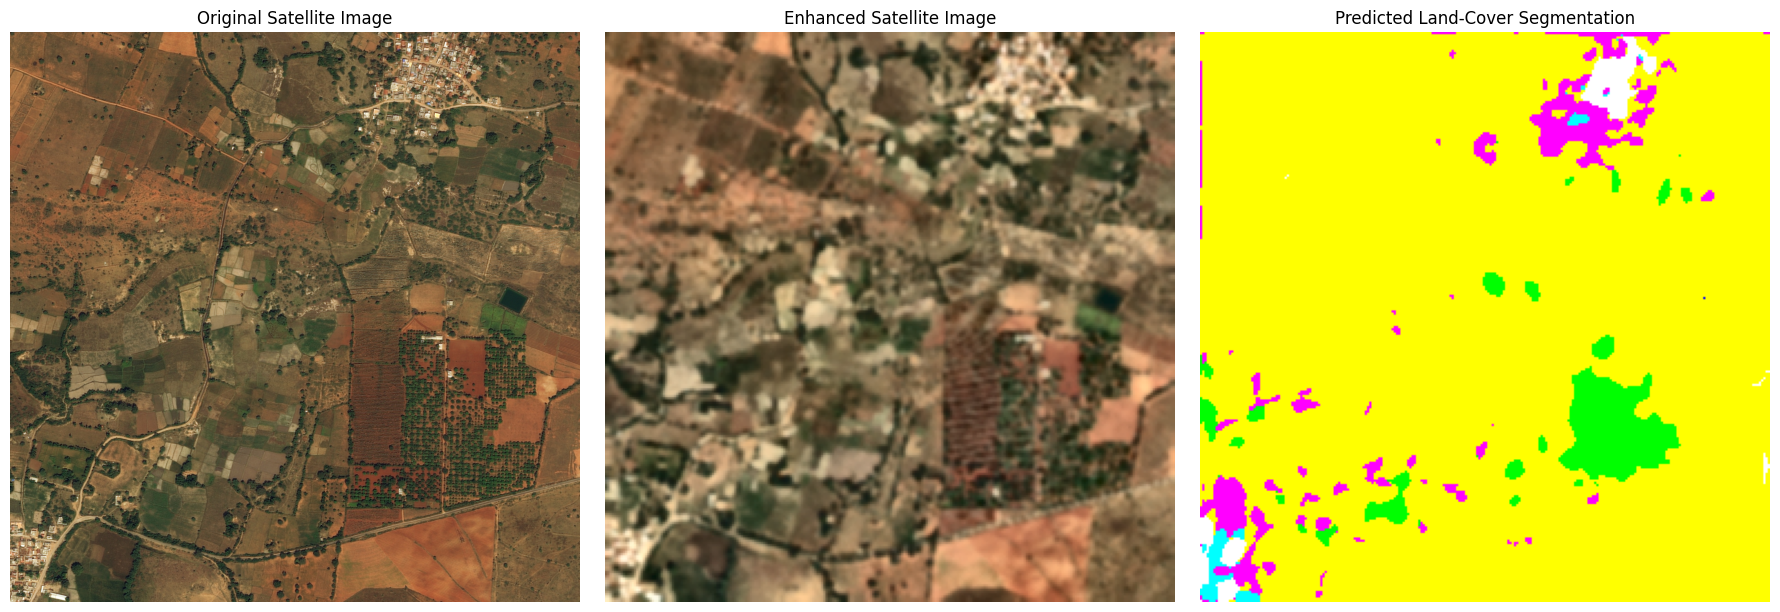


PREDICTED LAND-COVER DISTRIBUTION
urban_land           :    0.51%
agriculture_land     :   89.99%
rangeland            :    4.04%
forest_land          :    4.06%
water                :    0.00%
barren_land          :    1.39%
unknown              :    0.00%

Satellite image segmentation completed!


In [ ]:

# Step 49: Create the reusable satellite image inference pipeline

import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import os

from google.colab import files
from IPython.display import display

# Load the saved Experimental U-Net if not already loaded
FINAL_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "final_rangeland_experimental_unet.keras"
)

if "best_experimental_model" not in globals():
    best_experimental_model = tf.keras.models.load_model(
        FINAL_MODEL_PATH,
        compile=False
    )

print("Experimental U-Net ready for inference!")


# Image preprocessing function
def preprocess_new_satellite_image(image_path):

    # Read image using OpenCV
    image = cv2.imread(image_path)

    if image is None:
        raise ValueError("Unable to read the uploaded image.")

    # Convert BGR to RGB
    image_rgb = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    # Resize image
    resized_image = cv2.resize(
        image_rgb,
        (IMAGE_SIZE, IMAGE_SIZE),
        interpolation=cv2.INTER_LINEAR
    )

    # Apply Gaussian Blur
    blurred_image = cv2.GaussianBlur(
        resized_image,
        (5, 5),
        0
    )

    # Convert RGB to LAB
    lab_image = cv2.cvtColor(
        blurred_image,
        cv2.COLOR_RGB2LAB
    )

    # Apply CLAHE
    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    lab_image[:, :, 0] = clahe.apply(
        lab_image[:, :, 0]
    )

    # Convert LAB back to RGB
    enhanced_image = cv2.cvtColor(
        lab_image,
        cv2.COLOR_LAB2RGB
    )

    # Normalize image
    normalized_image = (
        enhanced_image.astype(np.float32) / 255.0
    )

    return image_rgb, enhanced_image, normalized_image


# Upload a satellite image
print("\nUpload a satellite image for segmentation:")

uploaded = files.upload()

if uploaded:

    uploaded_filename = next(iter(uploaded))

    # Save uploaded image
    with open(uploaded_filename, "wb") as f:
        f.write(uploaded[uploaded_filename])

    # Preprocess uploaded image
    original_image, enhanced_image, model_input = (
        preprocess_new_satellite_image(uploaded_filename)
    )

    # Generate segmentation prediction
    prediction = best_experimental_model.predict(
        np.expand_dims(model_input, axis=0),
        verbose=0
    )

    predicted_mask = np.argmax(
        prediction[0],
        axis=-1
    )

    # Convert predicted mask to RGB
    color_palette = np.array(
        [id_to_color[i] for i in range(NUM_CLASSES)],
        dtype=np.uint8
    )

    predicted_rgb_mask = color_palette[predicted_mask]

    # Display results
    fig, axes = plt.subplots(
        1, 3,
        figsize=(18, 6)
    )

    axes[0].imshow(original_image)
    axes[0].set_title("Original Satellite Image")

    axes[1].imshow(enhanced_image)
    axes[1].set_title("Enhanced Satellite Image")

    axes[2].imshow(predicted_rgb_mask)
    axes[2].set_title("Predicted Land-Cover Segmentation")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    # Calculate predicted class distribution
    total_pixels = predicted_mask.size

    print("\nPREDICTED LAND-COVER DISTRIBUTION")
    print("=" * 65)

    for class_id, class_name in enumerate(class_names):

        pixel_count = np.sum(
            predicted_mask == class_id
        )

        percentage = (
            pixel_count / total_pixels
        ) * 100

        print(
            f"{class_name:<20} : "
            f"{percentage:7.2f}%"
        )

    print("\nSatellite image segmentation completed!")

else:
    print("No image was uploaded.")


In [2]:

# Step 51: Compare prediction with the DeepGlobe ground-truth mask

import os
import cv2
import matplotlib.pyplot as plt

# Identify the uploaded satellite image
uploaded_stem = os.path.basename(
    uploaded_filename
).replace("_sat.jpg", "")

# Find its corresponding validation mask
matching_masks = [
    str(path)
    for path in val_masks
    if os.path.basename(str(path)).split("_mask")[0] == uploaded_stem
]

if not matching_masks:

    print("Matching ground-truth mask not found in validation dataset.")
    print("Please verify whether this image belongs to the validation set.")

else:

    ground_truth_path = matching_masks[0]

    # Read the ground-truth mask
    ground_truth = cv2.imread(ground_truth_path)

    ground_truth = cv2.cvtColor(
        ground_truth,
        cv2.COLOR_BGR2RGB
    )

    # Resize using nearest-neighbour interpolation
    ground_truth = cv2.resize(
        ground_truth,
        (IMAGE_SIZE, IMAGE_SIZE),
        interpolation=cv2.INTER_NEAREST
    )

    # Display ground truth and prediction
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    axes[0].imshow(ground_truth)
    axes[0].set_title("DeepGlobe Ground Truth")

    axes[1].imshow(predicted_rgb_mask)
    axes[1].set_title("Experimental U-Net Prediction")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    print("Ground-truth mask:", ground_truth_path)
    print("Comparison completed!")


NameError: name 'uploaded_filename' is not defined